<a href="https://colab.research.google.com/github/simichakravarty16/walmart-hurricane-project/blob/main/notebooks/team_notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Walmart Harricane Midterm Project
Group Members: Simi Chakravarty and Xiangyu Shi

## Introduction

Description of the project and the dataset we will use

### 1. Import Libraries

In [1]:
import pandas as pd
import os
import sqlite3
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests, time

### 2. Define Decision log



In [2]:
DECISIONS = []

def log(dataset, step, decision, rows_affected):
    DECISIONS.append({'dataset': dataset, 'step': step, 'decision': decision, 'rows': rows_affected})
    print(f'[{dataset}] [{step}] {decision} ({rows_affected} row(s))')

### 3. Data Setup

In [3]:
# Set data directory
DATA_DIR = '/content'

# Define data loading function
def load_data(filename):
  return pd.read_csv(os.path.join(DATA_DIR, filename))

### 4. Data Cleaning

#### 4.1 Walmart Transactions

In [4]:
# Load walmart transactions dataset
transactions = load_data('walmart_transactions.csv')
transactions.head()

,transaction_id,store_id,timestamp,sku,product_name,category,quantity,unit_price
0,TXN012636,FL-710,2024-09-24T09:48:13,PNUTBTR-16,PEANUT BUTTER,Grocery,1,3.15
1,TXN000759,fl-412,2024-09-13 20:30:20,CNSOUP-01,CANNED SOUP,GROCERY,1,2.02
2,TXN003338,FL-105,2024-09-17 10:06:00,TOILETPAPER12,Toilet Paper 12-Roll,Household Essentials,2,10.47
3,TXN025020,FL-330,2024-09-11 06:29:08,ROKU-STD,Roku Streaming Stick,ELECTRONICS,1,28.59
4,TXN015797,FL-302,2024-09-26 15:59:42,BEER-24,Light Beer 24pk,Alcoholic Beverages,3,18.82


In [5]:
# Count number of rows in the dataset
raw_rows = len(transactions)
print('starting with', raw_rows, 'rows')
print()

# Take inventory
transactions.info()

starting with 25562 rows

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25562 entries, 0 to 25561
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   transaction_id  25562 non-null  object
 1   store_id        25562 non-null  object
 2   timestamp       24676 non-null  object
 3   sku             25562 non-null  object
 4   product_name    25562 non-null  object
 5   category        25562 non-null  object
 6   quantity        25562 non-null  int64 
 7   unit_price      25562 non-null  object
dtypes: int64(1), object(7)
memory usage: 1.6+ MB


In [6]:
transactions.describe()

,quantity
count,25562.000000
mean,1.932634
std,1.086926
min,-5.000000
25%,1.000000
50%,2.000000
75%,2.000000
max,6.000000


In [7]:
print('shape:', transactions.shape)
print()
print('dtypes:', transactions.dtypes)
print()
print('nulls:', transactions.isnull().sum())
print()
print('duplicates:', transactions.duplicated().sum())

shape: (25562, 8)

dtypes: transaction_id    object
store_id          object
timestamp         object
sku               object
product_name      object
category          object
quantity           int64
unit_price        object
dtype: object

nulls: transaction_id      0
store_id            0
timestamp         886
sku                 0
product_name        0
category            0
quantity            0
unit_price          0
dtype: int64

duplicates: 30


In [8]:
# Inspect unique SKUs, product names, and categories
print('unique SKUs:', transactions['sku'].nunique())
print('unique SKUs:', transactions['sku'].unique())
print()
print('unique product names:', transactions['product_name'].nunique())
print()
print('unique categories:', transactions['category'].nunique())

unique SKUs: 45
unique SKUs: ['PNUTBTR-16' 'CNSOUP-01' 'TOILETPAPER12' 'ROKU-STD' 'BEER-24'
 'CHIPVARIETY' 'TARP-HD' 'PAPERTOWEL6' 'CANDLE-EMRG' 'CARDS-01' 'CHIPS-VP'
 'HDTARP-01' 'WHITEBREAD' 'PORTCHARGER' 'PTOWEL-6' 'FIRSTAID-KIT'
 'PT_STRAWBERRY' 'LTBEER24' 'FLASH-01' 'PB-16' 'SKU#459812' 'BATT_AA_4PK'
 'BFORM-01' 'WTR-24' 'STREAM-01' 'BATT-100' 'CNDL-EM' 'TP-12' 'PT-12'
 'BABYFORMULA' 'DIAP-S3' 'POPTART-STRAW' 'DIAPERS-3' 'SOUP-CAN'
 'PLAYCARD-STD' 'WATER24PK' 'CHRG-PORT' 'BG-MONO' 'MONOPOLY-01' 'BAT-AA4'
 'LED-FLASH' 'FAID-01' 'BREAD-WH' 'GAME-MONO' 'WTR_24PK']

unique product names: 63

unique categories: 37


Problems:
1. There are 30 duplicate rows in the dataset.
2. There are 886 nulls in the `timestamp` column. Missing values are represented in several ways, including empty strings, `NULL`, `N/A`, `NaN`, and `nan`.
3. Dates and times are in different formats in the `timestamp` column.
4. The same products appear under different SKUs and product names.
5. There are inconsistencies in capitalization and spacing.
6. The same products have different category names.
7. The `unit_price` column is stored as `str` instead of `float`, and some values  contains `$` signs.
8. There are negative quantities in the `quantity` column.  
9. The `store_id` column does not consistently follow the `FL-#` format.

In [9]:
# Transform: Types and Duplicates
def transform_types(df):
    out = df.copy()

    # Drop duplicates
    before = len(out)
    out = out.drop_duplicates()
    removed = before - len(out)
    log('walmart_transactions', 'remove duplicates', 'Removed duplicate rows', removed)

    # Normalize timestamps
    out['timestamp'] = pd.to_datetime(out['timestamp'], errors='coerce', format='mixed')
    missing = out['timestamp'].isna().sum()
    log('walmart_transactions', 'clean timestamp', 'Converted timestamps to datetime and kept missing values as NaT', missing)

    # Create date column for joining with daily weather data
    out['date'] = out['timestamp'].dt.normalize()
    log('walmart_transactions', 'create date column', 'Extracted calendar date from timestamp for weather merge', out['date'].notna().sum())

    # Convert unit_price to float (no $ sign)
    out['unit_price'] = (out['unit_price'].astype(str)
                         .str.replace('$', '', regex=False) # remove $ sign
                         .str.strip().astype(float))    # change unit prices to float
    affected_price = len(out)
    log('walmart_transactions', 'clean unit_price', 'Removed $ sign and converted unit_price to float', affected_price)

    # Clean quantity
    before = len(out)
    out['quantity'] = pd.to_numeric(out['quantity'], errors='coerce')
    # Decision: drop the unparseable quantity and the return. We are measuring
    # units that left the shelf ahead of the hurricane, so a return is not that.
    out = out[out['quantity'].notna() & (out['quantity'] > 0)].copy()
    out['quantity'] = out['quantity'].astype(int)
    removed_quantity = before - len(out)
    log('walmart_transactions', 'clean quantity', 'Removed negative quantities (returns)', removed_quantity)

    # Standardize store_id
    old_id = out['store_id'].copy()
    out['store_id'] = out['store_id'].astype(str).str.upper().str.strip().str.replace(r'^FL[\s_-]*(\d+)$', r'FL-\1', regex=True)
    affected_id = (old_id != out['store_id']).sum()
    log('walmart_transactions', 'clean store_id', 'Standardized store IDs to FL-# format', affected_id)

    return out

In [10]:
# Transform: consolidate SKUs, product names, and categories

# Consolidate SKUs
SKU_MAP = {
    'BATT_AA_4PK': 'BAT-AA4',
    'BATT-100': 'BAT-AA4',
    'BEER-24': 'LTBEER24',
    'BABYFORMULA': 'BFORM-01',
    'BG-MONO': 'BG-MONO-01',
    'MONOPOLY-01': 'BG-MONO-01',
    'GAME-MONO': 'BG-MONO-01',
    'BREAD-WH': 'WHITEBREAD',
    'CNDL-EM': 'CANDLE-EMRG',
    'PLAYCARD-STD': 'CARDS-01',
    'CHIPVARIETY': 'CHIPS-VP',
    'PORTCHARGER': 'CHRG-PORT',
    'SOUP-CAN': 'CNSOUP-01',
    'DIAPERS-3': 'DIAP-S3',
    'FIRSTAID-KIT': 'FAID-01',
    'LED-FLASH': 'FLASH-01',
    'TARP-HD': 'HDTARP-01',
    'PAPERTOWEL6': 'PTOWEL6',
    'PTOWEL-6': 'PTOWEL6',
    'TOILETPAPER12': 'TOILETPAPER-12',
    'TP-12': 'TOILETPAPER-12',
    'PB-16': 'PNUTBTR-16',
    'PT-12': 'POPTART-STRAW',
    'SKU#459812': 'POPTART-STRAW',
    'PT_STRAWBERRY': 'POPTART-STRAW',
    'ROKU-STD': 'ROKU-STREAM',
    'STREAM-01': 'ROKU-STREAM',
    'WATER24PK': 'WATER-24',
    'WTR_24PK': 'WATER-24',
    'WTR-24': 'WATER-24'
}

# Standardize product names
PRODUCT_MAP = {
    'BAT-AA4': 'Batteries AA 4PK',
    'LTBEER24': 'Light Beer 24PK',
    'BFORM-01': 'Baby Formula',
    'BG-MONO-01': 'Monopoly Board Game',
    'WHITEBREAD': 'White Bread',
    'CANDLE-EMRG': 'Emergency Candle',
    'CARDS-01': 'Playing Cards',
    'CHIPS-VP': 'Chip Variety Pack',
    'CHRG-PORT': 'Portable Phone Charger',
    'CNSOUP-01': 'Canned Soup',
    'DIAP-S3': 'Diapers Size 3',
    'FAID-01': 'First Aid Kit',
    'FLASH-01': 'LED Flashlight',
    'HDTARP-01': 'Heavy Duty Tarp',
    'PTOWEL6': 'Paper Towels 6PK',
    'TOILETPAPER-12': 'Toilet Paper 12PK',
    'PNUTBTR-16': 'Peanut Butter 16oz',
    'POPTART-STRAW': 'Pop-Tarts Strawberry',
    'ROKU-STREAM': 'Roku Streaming Stick',
    'WATER-24': 'Bottled Water 24PK'
}

# Standardize categories
CATEGORY_MAP = {
    'Alcoholic Beverages': 'Alcohol',
    'Baby Products': 'Baby',
    'Breakfast Foods': 'Breakfast',
    'Emergency Supplies': 'Emergency',
    'Groceries': 'Grocery',
    'Games & Entertainment': 'Entertainment',
    'Health & Wellness': 'Health',
    'Household Essentials': 'Household'
}

def consolidate_transactions(df):
    out = df.copy()

    # Consolidate SKUs
    old_sku = out['sku'].copy()
    out['sku'] = out['sku'].map(SKU_MAP).fillna(out['sku'])
    affected_sku = (old_sku != out['sku']).sum()
    log('walmart_transactions', 'clean sku', 'Consolidated SKUs so the same products share the same SKU', affected_sku)

    # Standardize product names
    old_name = out['product_name'].copy()
    out['product_name'] = out['sku'].map(PRODUCT_MAP).fillna(out['product_name'])
    affected_name = (old_name != out['product_name']).sum()
    log('walmart_transactions', 'clean product_name', 'Standardized product names based on SKUs for consistency', affected_name)

    # Standardize categories
    old_category = out['category'].copy()
    out['category'] = out['category'].str.strip().str.title().replace(CATEGORY_MAP)
    affected_category = (old_category != out['category']).sum()
    log('walmart_transactions', 'clean category', 'Standardized category names, capitalization, and spacing', affected_category)

    return out

In [11]:
def clean_walmart_transactions(df):
    df = transform_types(df)
    df = consolidate_transactions(df)
    return df

clean_transactions = clean_walmart_transactions(transactions)
display(clean_transactions.head())

print('Shape:', clean_transactions.shape)
print('\nData Types:')
print(clean_transactions.dtypes)
print()

# Check number of rows before and after cleaning
print('Rows before cleaning:', len(transactions))
print('Rows after cleaning:', len(clean_transactions))
print('Rows removed:', len(transactions) - len(clean_transactions))
print()

# Validate consolidation
print('unique SKUs after:', clean_transactions['sku'].nunique())
print('unique product names after:', clean_transactions['product_name'].nunique())
print('unique categories after:', clean_transactions['category'].nunique())

[walmart_transactions] [remove duplicates] Removed duplicate rows (30 row(s))
[walmart_transactions] [clean timestamp] Converted timestamps to datetime and kept missing values as NaT (884 row(s))
[walmart_transactions] [create date column] Extracted calendar date from timestamp for weather merge (24648 row(s))
[walmart_transactions] [clean unit_price] Removed $ sign and converted unit_price to float (25532 row(s))
[walmart_transactions] [clean quantity] Removed negative quantities (returns) (130 row(s))
[walmart_transactions] [clean store_id] Standardized store IDs to FL-# format (4324 row(s))
[walmart_transactions] [clean sku] Consolidated SKUs so the same products share the same SKU (16702 row(s))
[walmart_transactions] [clean product_name] Standardized product names based on SKUs for consistency (20155 row(s))
[walmart_transactions] [clean category] Standardized category names, capitalization, and spacing (18649 row(s))


,transaction_id,store_id,timestamp,sku,product_name,category,quantity,unit_price,date
0,TXN012636,FL-710,2024-09-24 09:48:13,PNUTBTR-16,Peanut Butter 16oz,Grocery,1,3.15,2024-09-24
1,TXN000759,FL-412,2024-09-13 20:30:20,CNSOUP-01,Canned Soup,Grocery,1,2.02,2024-09-13
2,TXN003338,FL-105,2024-09-17 10:06:00,TOILETPAPER-12,Toilet Paper 12PK,Household,2,10.47,2024-09-17
3,TXN025020,FL-330,2024-09-11 06:29:08,ROKU-STREAM,Roku Streaming Stick,Electronics,1,28.59,2024-09-11
4,TXN015797,FL-302,2024-09-26 15:59:42,LTBEER24,Light Beer 24PK,Alcohol,3,18.82,2024-09-26


Shape: (25402, 9)

Data Types:
transaction_id            object
store_id                  object
timestamp         datetime64[ns]
sku                       object
product_name              object
category                  object
quantity                   int64
unit_price               float64
date              datetime64[ns]
dtype: object

Rows before cleaning: 25562
Rows after cleaning: 25402
Rows removed: 160

unique SKUs after: 20
unique product names after: 20
unique categories after: 10


In [12]:
# Validation for clean_transactions
assert clean_transactions.duplicated().sum() == 0
assert pd.api.types.is_datetime64_any_dtype(clean_transactions['timestamp'])
assert pd.api.types.is_float_dtype(clean_transactions['unit_price'])
assert (clean_transactions['quantity'] > 0).all()
assert clean_transactions['store_id'].str.fullmatch(r'FL-\d+').all()

# Validate SKUs and product names
assert clean_transactions['sku'].nunique() == clean_transactions['product_name'].nunique()
assert (clean_transactions.groupby('sku')['product_name'].nunique() == 1).all()
assert clean_transactions['category'].nunique() == 10

print('Walmart transactions validation passed!')

Walmart transactions validation passed!


Decisions:
1. We removed the 30 duplicate rows to avoid counting the same transactions more than once during analysis.
2. We converted `timestamp` column to datetime to ensure a consistent format. We used `format='mixed'` to handle different timestamp formats and `errors='coerce'` to convert missing or invalid timestamps to `NaT` instead of raising errors. We decided to keep rows with missing timestamps because they contain other useful transaction information. These rows will be excluded later from analyses that require transaction dates.
3. We created the date column for joining with daily weather data.
4. We removed the `$` sign from the `unit_price` column and converted the values from strings to floats so that we can use numerical values to calculate revenue later if needed.
5. We decided to remove rows with negative quantities because our analysis focuses on units sold ahead of the hurricane, and returns do not represent units leaving store shelves.
6. We standardized the `store_id`column to the `FL-#` format to ensure consistency and allow accurate merging with the `clean_stores` dataset.
7. We consolidated different SKUs representing the same products into one canonical SKU to ensure consistency and avoid treating them as different products during analysis.
8. We standardized `product_name` based on SKUs to ensure that the same products have consistent names and avoid treating them as different products during analysis.
9. We standardized the `category` column to ensure consistent category names and capitalization and avoid incorrect grouping during analysis.

#### 4.2 Product Catalog

In [13]:
products = load_data('product_catalog.csv')
products.head()

,sku,product_name,category,subcategory,unit_cost,supplier,package_size
0,PT-12,pop-tarts strawberry,Breakfast Foods,NaN,1.93,Johnson & Johnson,4-pack
1,SKU#459812,Strawberry Pop-Tart,Breakfast,Pop-Tarts,2.26,Roku Inc,4pk
2,POPTART-STRAW,Pop-Tarts Strawberry,Breakfast,NaN,2.11,Sara Lee,6 pack
3,PT_STRAWBERRY,pop-tarts strawberry,breakfast,Pop-Tarts,NaN,Campbell's,4 pack
4,WTR-24,BOTTLED WATER 24PK,Emergency Supplies,Bottled,2.64,Sara Lee,1 pack


In [14]:
# Count number of rows in the dataset
raw_rows = len(products)
print('starting with', raw_rows, 'rows')
print()

# Take inventory
products.info()

starting with 45 rows

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45 entries, 0 to 44
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sku           45 non-null     object 
 1   product_name  45 non-null     object 
 2   category      45 non-null     object 
 3   subcategory   32 non-null     object 
 4   unit_cost     40 non-null     float64
 5   supplier      45 non-null     object 
 6   package_size  45 non-null     object 
dtypes: float64(1), object(6)
memory usage: 2.6+ KB


In [15]:
products.describe()

,unit_cost
count,40.000000
mean,6.762500
std,5.460566
min,1.120000
25%,2.350000
50%,4.135000
75%,10.445000
max,18.870000


In [16]:
print('shape:', products.shape)
print()
print('dtypes:', products.dtypes)
print()
print('nulls:', products.isnull().sum())
print()
print('duplicates:', products.duplicated().sum())

shape: (45, 7)

dtypes: sku              object
product_name     object
category         object
subcategory      object
unit_cost       float64
supplier         object
package_size     object
dtype: object

nulls: sku              0
product_name     0
category         0
subcategory     13
unit_cost        5
supplier         0
package_size     0
dtype: int64

duplicates: 0


In [17]:
# Inspect unique SKUs, product names, and categories
print('unique SKUs:', products['sku'].nunique())
print('unique product names:', products['product_name'].nunique())
print('unique categories:', products['category'].nunique())

unique SKUs: 45
unique product names: 38
unique categories: 27


Problems:
1. The same products appear under different SKUs and product names.
2. The `category` column contains inconsistent category names and capitalization.
4. There are 13 nulls in the `subcategory` column and 5 nulls in the `unit_cost` column.
5. The `package-size` column contains inconsistent formatting.
6. Some equivalent products have different package sizes.
7. Some supplier assignments appear inconsistent with the types of products the suppliers typically provide.

In [18]:
# Transform: consolidate SKUs, product names, categories, subcategories, suppliers, and package sizes

# Consolidate SKUs
SKU_MAP = {
    'BATT_AA_4PK': 'BAT-AA4',
    'BATT-100': 'BAT-AA4',
    'BEER-24': 'LTBEER24',
    'BABYFORMULA': 'BFORM-01',
    'BG-MONO': 'BG-MONO-01',
    'MONOPOLY-01': 'BG-MONO-01',
    'GAME-MONO': 'BG-MONO-01',
    'BREAD-WH': 'WHITEBREAD',
    'CNDL-EM': 'CANDLE-EMRG',
    'PLAYCARD-STD': 'CARDS-01',
    'CHIPVARIETY': 'CHIPS-VP',
    'PORTCHARGER': 'CHRG-PORT',
    'SOUP-CAN': 'CNSOUP-01',
    'DIAPERS-3': 'DIAP-S3',
    'FIRSTAID-KIT': 'FAID-01',
    'LED-FLASH': 'FLASH-01',
    'TARP-HD': 'HDTARP-01',
    'PAPERTOWEL6': 'PTOWEL6',
    'PTOWEL-6': 'PTOWEL6',
    'TOILETPAPER12': 'TOILETPAPER-12',
    'TP-12': 'TOILETPAPER-12',
    'PB-16': 'PNUTBTR-16',
    'PT-12': 'POPTART-STRAW',
    'SKU#459812': 'POPTART-STRAW',
    'PT_STRAWBERRY': 'POPTART-STRAW',
    'ROKU-STD': 'ROKU-STREAM',
    'STREAM-01': 'ROKU-STREAM',
    'WATER24PK': 'WATER-24',
    'WTR_24PK': 'WATER-24',
    'WTR-24': 'WATER-24'
}

# Standardize product names
PRODUCT_MAP = {
    'BAT-AA4': 'Batteries AA 4PK',
    'LTBEER24': 'Light Beer 24PK',
    'BFORM-01': 'Baby Formula',
    'BG-MONO-01': 'Monopoly Board Game',
    'WHITEBREAD': 'White Bread',
    'CANDLE-EMRG': 'Emergency Candle',
    'CARDS-01': 'Playing Cards',
    'CHIPS-VP': 'Chip Variety Pack',
    'CHRG-PORT': 'Portable Phone Charger',
    'CNSOUP-01': 'Canned Soup',
    'DIAP-S3': 'Diapers Size 3',
    'FAID-01': 'First Aid Kit',
    'FLASH-01': 'LED Flashlight',
    'HDTARP-01': 'Heavy Duty Tarp',
    'PTOWEL6': 'Paper Towels 6PK',
    'TOILETPAPER-12': 'Toilet Paper 12PK',
    'PNUTBTR-16': 'Peanut Butter 16oz',
    'POPTART-STRAW': 'Pop-Tarts Strawberry',
    'ROKU-STREAM': 'Roku Streaming Stick',
    'WATER-24': 'Bottled Water 24PK'
}

# Standardize categories
CATEGORY_MAP = {
    'Alcoholic Beverages': 'Alcohol',
    'Baby Products': 'Baby',
    'Breakfast Foods': 'Breakfast',
    'Emergency Supplies': 'Emergency',
    'Groceries': 'Grocery',
    'Games & Entertainment': 'Entertainment',
    'Health & Wellness': 'Health',
    'Household Essentials': 'Household'
}

# Standardize subcategories
SUBCATEGORY_MAP = {
    'BAT-AA4': 'Batteries',
    'LTBEER24': 'Beer',
    'BFORM-01': 'Formula',
    'BG-MONO-01': 'Board Games',
    'WHITEBREAD': 'Bread',
    'CANDLE-EMRG': 'Candles',
    'CARDS-01': 'Card Games',
    'CHIPS-VP': 'Chips',
    'CHRG-PORT': 'Charger',
    'CNSOUP-01': 'Soup',
    'DIAP-S3': 'Diapers',
    'FAID-01': 'First Aid',
    'FLASH-01': 'Flashlight',
    'HDTARP-01': 'Tarps',
    'PTOWEL6': 'Paper Towels',
    'TOILETPAPER-12': 'Toilet Paper',
    'PNUTBTR-16': 'Peanut Butter',
    'POPTART-STRAW': 'Pop-Tarts',
    'ROKU-STREAM': 'Streaming',
    'WATER-24': 'Bottled Water'
}

# Standardize suppliers
SUPPLIER_MAP = {
    'BAT-AA4': 'Generic Supplier',
    'LTBEER24': 'Anheuser-Busch',
    'BFORM-01': 'Generic Supplier',
    'BG-MONO-01': 'Hasbro',
    'WHITEBREAD': 'Sara Lee',
    'CANDLE-EMRG': 'Generic Supplier',
    'CARDS-01': 'Hasbro',
    'CHIPS-VP': 'Frito-Lay',
    'CHRG-PORT': 'Generic Supplier',
    'CNSOUP-01': "Campbell's",
    'DIAP-S3': 'Procter & Gamble',
    'FAID-01': 'Johnson & Johnson',
    'FLASH-01': 'Generic Supplier',
    'HDTARP-01': '3M Company',
    'PTOWEL6': 'Georgia-Pacific',
    'TOILETPAPER-12': 'Kimberly-Clark',
    'PNUTBTR-16': 'J.M. Smucker',
    'POPTART-STRAW': "Kellogg's",
    'ROKU-STREAM': 'Roku Inc',
    'WATER-24': 'Generic Supplier'
}

# Standardize package sizes
PACKAGE_MAP = {
    'BAT-AA4': '4-pack',
    'LTBEER24': '24-pack',
    'BFORM-01': '1-pack',
    'BG-MONO-01': '1-pack',
    'WHITEBREAD': '1-pack',
    'CANDLE-EMRG': '1-pack',
    'CARDS-01': '1-pack',
    'CHIPS-VP': '6-pack',
    'CHRG-PORT': '1-pack',
    'CNSOUP-01': '1-pack',
    'DIAP-S3': '1-pack',
    'FAID-01': '1-pack',
    'FLASH-01': '1-pack',
    'HDTARP-01': '1-pack',
    'PTOWEL6': '6-pack',
    'TOILETPAPER-12': '12-pack',
    'PNUTBTR-16': '1-pack',
    'POPTART-STRAW': '8-pack',
    'ROKU-STREAM': '1-pack',
    'WATER-24': '24-pack'
}

def consolidated_products(df):
    out = df.copy()

    # Consolidate SKUs
    old_sku = out['sku'].copy()
    out['sku'] = out['sku'].map(SKU_MAP).fillna(out['sku'])
    affected_sku = (old_sku != out['sku']).sum()
    log('product_catalog', 'clean sku', 'Consolidated SKUs so the same products share the same SKU', affected_sku)

    # Standardize product names
    old_name = out['product_name'].copy()
    out['product_name'] = out['sku'].map(PRODUCT_MAP).fillna(out['product_name'])
    affected_name = (old_name != out['product_name']).sum()
    log('product_catalog', 'clean product_name', 'Standardized product names based on SKUs for consistency', affected_name)

    # Standardize categories
    old_category = out['category'].copy()
    out['category'] = out['category'].str.strip().str.title().replace(CATEGORY_MAP)
    affected_category = (old_category != out['category']).sum()
    log('product_catalog', 'clean category', 'Standardized category names and capitalization', affected_category)

    # Standardize subcategories
    old_subcategory = out['subcategory'].copy()
    out['subcategory'] = out['sku'].map(SUBCATEGORY_MAP).fillna(out['subcategory'])
    affected_subcategory = (old_subcategory != out['subcategory']).sum()
    log('product_catalog', 'clean subcategory', 'Standardized subcategory names based on SKUs for consistency', affected_subcategory)

    # Keep rows with missing unit_cost
    missing = out['unit_cost'].isna().sum()
    log('product_catalog', 'keep missing unit_cost', 'Kept rows with missing unit_cost', missing)

    # Standardize suppliers
    old_supplier = out['supplier'].copy()
    out['supplier'] = out['sku'].map(SUPPLIER_MAP).fillna(out['supplier'])
    affected_supplier = (old_supplier != out['supplier']).sum()
    log('product_catalog', 'clean supplier', 'Standardized supplier names based on SKUs for consistency', affected_supplier)

    # Standardize package sizes
    old_package = out['package_size'].copy()
    out['package_size'] = out['sku'].map(PACKAGE_MAP).fillna(out['package_size'])
    affected_package = (old_package != out['package_size']).sum()
    log('product_catalog', 'clean package_size', 'Standardized package sizes based on SKUs for consistency', affected_package)

    return out

In [19]:
clean_products = consolidated_products(products)
clean_products.head()

[product_catalog] [clean sku] Consolidated SKUs so the same products share the same SKU (30 row(s))
[product_catalog] [clean product_name] Standardized product names based on SKUs for consistency (35 row(s))
[product_catalog] [clean category] Standardized category names and capitalization (32 row(s))
[product_catalog] [clean subcategory] Standardized subcategory names based on SKUs for consistency (32 row(s))
[product_catalog] [keep missing unit_cost] Kept rows with missing unit_cost (5 row(s))
[product_catalog] [clean supplier] Standardized supplier names based on SKUs for consistency (41 row(s))
[product_catalog] [clean package_size] Standardized package sizes based on SKUs for consistency (44 row(s))


,sku,product_name,category,subcategory,unit_cost,supplier,package_size
0,POPTART-STRAW,Pop-Tarts Strawberry,Breakfast,Pop-Tarts,1.93,Kellogg's,8-pack
1,POPTART-STRAW,Pop-Tarts Strawberry,Breakfast,Pop-Tarts,2.26,Kellogg's,8-pack
2,POPTART-STRAW,Pop-Tarts Strawberry,Breakfast,Pop-Tarts,2.11,Kellogg's,8-pack
3,POPTART-STRAW,Pop-Tarts Strawberry,Breakfast,Pop-Tarts,NaN,Kellogg's,8-pack
4,WATER-24,Bottled Water 24PK,Emergency,Bottled Water,2.64,Generic Supplier,24-pack


In [20]:
# Validation for clean_products
assert clean_products.duplicated().sum() == 0
assert clean_products['sku'].nunique() == 20

for col in ['product_name', 'category', 'subcategory',
            'supplier', 'package_size']:
    assert (clean_products.groupby('sku')[col].nunique() == 1).all()

assert clean_products[
    ['sku', 'product_name', 'category', 'subcategory',
     'supplier', 'package_size']
].notna().all().all()

assert pd.api.types.is_float_dtype(clean_products['unit_cost'])
assert clean_products['unit_cost'].isna().sum() == 5
assert (clean_products['unit_cost'].dropna() > 0).all()

print("Product catalog validation passed!")

Product catalog validation passed!


Decisions:
1. We consolidated different SKUs representing the same products into one canonical SKU to ensure consistency and avoid treating them as different products during analysis.
2. We standardized `product_name` based on SKUs to ensure that the same products have consistent names and avoid treating them as different products during analysis.
3. We standardized the `category` column to ensure consistent category names and capitalization and avoid incorrect grouping during analysis.
4. We standardized `subcategory` based on SKUs to ensure that the same products have consistent subcategories. We also filled missing subcategory values using the standardized SKU mappings.
5. We decided to keep the five rows with missing `unit_cost` values because they contain other useful product information. We also kept the different unit costs for the same products because costs may vary across different periods, and there is not enough information to determine which values are correct.
6. We standardized `supplier` based on SKUs to ensure consistent supplier assignments for the same products. We selected suppliers based on research into the types of products these companies typically provide.
7. We standardized `package_size` based on SKUs to ensure that the same products have consistent package sizes. We selected reasonable package sizes based on product descriptions, SKUs, and available unit costs and online research.



#### 4.3 Store Locations

In [21]:
# Load store locations dataset
stores = load_data('store_locations.csv')
stores.head()

,store_id,store_name,city,state,zip_code,latitude,longitude,region
0,FL-239,Walmart Supercenter Orlando,Orlando,FL,32801,28.5383,-81.3792,Central
1,FL-105,Walmart Supercenter Tampa,Tampa,FL,33602,27.9506,-82.4572,West
2,FL-330,Walmart Supercenter Miami,Miami,FL,33101,25.7617,-80.1918,South
3,FL-412,Walmart Supercenter Jacksonville,Jacksonville,FL,32099,30.3322,-81.6557,North
4,FL-287,Walmart Neighborhood Market Kissimmee,Kissimmee,Florida,34741,28.2920,-81.4076,Central


In [22]:
# Count number of rows in the dataset
raw_rows = len(stores)
print('starting with', raw_rows, 'rows')
print()

# Take inventory
stores.info()

starting with 14 rows

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14 entries, 0 to 13
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   store_id    14 non-null     object 
 1   store_name  14 non-null     object 
 2   city        14 non-null     object 
 3   state       14 non-null     object 
 4   zip_code    14 non-null     int64  
 5   latitude    13 non-null     float64
 6   longitude   13 non-null     float64
 7   region      14 non-null     object 
dtypes: float64(2), int64(1), object(5)
memory usage: 1.0+ KB


In [23]:
stores.describe()

,zip_code,latitude,longitude
count,14.000000,13.000000,13.000000
mean,33200.428571,28.418192,-82.069631
std,893.995759,1.319349,1.676108
min,32099.000000,25.761700,-87.216900
25%,32526.000000,27.950600,-82.324800
50%,32951.000000,28.292000,-81.655700
75%,33776.000000,29.210800,-81.379200
max,34741.000000,30.421300,-80.191800


In [24]:
print('shape:', stores.shape)
print()
print('dtypes:', stores.dtypes)
print()
print('nulls:', stores.isnull().sum())
print()
print('duplicates:', stores.duplicated().sum())

shape: (14, 8)

dtypes: store_id       object
store_name     object
city           object
state          object
zip_code        int64
latitude      float64
longitude     float64
region         object
dtype: object

nulls: store_id      0
store_name    0
city          0
state         0
zip_code      0
latitude      1
longitude     1
region        0
dtype: int64

duplicates: 0


Problems:
1. The `store_id` column does not consistently follow the `FL-#` format.
2. Not all values in the `state` column are written as `FL`.  
3. The `zip_code` column is stored as `int` instead of `str`.
4. There is a leading space before `Panhandle` in the `region` column for `FL-619`.
5. Some records represent the same store but have different store_id formats, resulting in duplicate stores.
6. There is one null in each of the `latitude` and `longitude` column for store `FL-619`.



In [25]:
def clean_store_locations(df):
    out = df.copy()

    # Standardize store_id
    old_id = out['store_id'].copy()
    out['store_id'] = out['store_id'].astype(str).str.upper().str.strip().str.replace(r'^FL[\s_-]*(\d+)$', r'FL-\1', regex=True)
    affected = (old_id != out['store_id']).sum()
    log('store_locations', 'clean store_id', 'Standardized store IDs to FL-# format', affected)

    # Standardize state
    out_state = out['state'].copy()
    out['state'] = out['state'].str.strip().str.upper().replace({'FLORIDA': 'FL', 'FLA.': 'FL'})
    affected = (out_state != out['state']).sum()
    log('store_locations', 'clean state', 'Standardized Florida values to FL', affected)

    # Convert zip_code to string
    out['zip_code'] = out['zip_code'].astype(str)
    log('store_locations', 'clean zip_code', 'Converted zip_code to string', len(out))

    # Remove leading and trailing spaces from region
    old_region = out['region'].copy()
    out['region'] = out['region'].str.strip()
    affected = (old_region != out['region']).sum()
    log('store_locations', 'clean region', 'Removed leading and trailing spaces from region', affected)

    # Remove duplicate stores
    before = len(out)
    out = out.drop_duplicates(subset=('store_id')).copy()
    removed = before - len(out)
    log('store_locations', 'remove duplicates', 'Removed duplicate stores with the same store_id', removed)

    # Keep missing coordinates
    missing = out[['latitude', 'longitude']].isna().any(axis=1).sum()
    log('store_locations', 'keep missing coordinates', 'Kept rows with missing latitude and/or longitude', missing)

    return out

In [26]:
clean_stores = clean_store_locations(stores)
clean_stores.head()

[store_locations] [clean store_id] Standardized store IDs to FL-# format (2 row(s))
[store_locations] [clean state] Standardized Florida values to FL (4 row(s))
[store_locations] [clean zip_code] Converted zip_code to string (14 row(s))
[store_locations] [clean region] Removed leading and trailing spaces from region (1 row(s))
[store_locations] [remove duplicates] Removed duplicate stores with the same store_id (2 row(s))
[store_locations] [keep missing coordinates] Kept rows with missing latitude and/or longitude (1 row(s))


,store_id,store_name,city,state,zip_code,latitude,longitude,region
0,FL-239,Walmart Supercenter Orlando,Orlando,FL,32801,28.5383,-81.3792,Central
1,FL-105,Walmart Supercenter Tampa,Tampa,FL,33602,27.9506,-82.4572,West
2,FL-330,Walmart Supercenter Miami,Miami,FL,33101,25.7617,-80.1918,South
3,FL-412,Walmart Supercenter Jacksonville,Jacksonville,FL,32099,30.3322,-81.6557,North
4,FL-287,Walmart Neighborhood Market Kissimmee,Kissimmee,FL,34741,28.2920,-81.4076,Central


In [27]:
# Validation for clean_stores
assert clean_stores['store_id'].is_unique
assert clean_stores['store_id'].str.fullmatch(r'FL-\d+').all()
assert (clean_stores['state'] == 'FL').all()
assert pd.api.types.is_string_dtype(clean_stores['zip_code'])
assert clean_stores['region'].eq(clean_stores['region'].str.strip()).all()

print("Store locations validation passed!")

Store locations validation passed!


Decisions:
1. We standardized the `store_id` column to the `FL-#` format to ensure consistency and allow accurate merging with the `clean_transactions` dataset.
2. We standardized the `state` column to `FL` to ensure consistent formatting for all Florida store locations.
3. We converted the `zip_code` column to strings because ZIP codes are identifiers rather than numerical values. This also preserves any leading zeros if present.
4. We removed leading and trailing spaces from the `region` column to ensure consistent region names and avoid incorrect grouping during analysis.
5. We removed duplicate rows with the same `store_id` after standardizing the IDs to ensure each store is represented only once and prevent duplicated records when merging datasets.
6. We decided to keep the row with missing `latitude` and `longitude` values because removing it would result in losing other useful information about the store that may be needed for further analysis.

#### 4.4 Distribution Centers

In [28]:
# Load distribution centers dataset
dc = load_data('distribution_centers.csv')
dc

,dc_id,dc_name,city,state,avg_daily_shipments,surge_capacity,distance_to_orlando_mi,cost_per_shipment
0,DC-JAX,Jacksonville Distribution Center,Jacksonville,FL,500,1000,141,245.0
1,DC-ATL,Atlanta Distribution Center,Atlanta,GA,400,700,438,412.5
2,DC-DAL,Dallas Distribution Center,Dallas,TX,300,600,1108,687.0
3,DC-MIA,Miami Distribution Center,Miami,FL,350,~750,235,298.0
4,DC-BHM,Birmingham Distribution Center,Birmingham,AL,250,500,503,NaN


In [29]:
# Count number of rows in the dataset
raw_rows = len(dc)
print('starting with', raw_rows, 'rows')
print()

# Take inventory
dc.info()

starting with 5 rows

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 8 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   dc_id                   5 non-null      object 
 1   dc_name                 5 non-null      object 
 2   city                    5 non-null      object 
 3   state                   5 non-null      object 
 4   avg_daily_shipments     5 non-null      int64  
 5   surge_capacity          5 non-null      object 
 6   distance_to_orlando_mi  5 non-null      int64  
 7   cost_per_shipment       4 non-null      float64
dtypes: float64(1), int64(2), object(5)
memory usage: 452.0+ bytes


In [30]:
dc.describe()

,avg_daily_shipments,distance_to_orlando_mi,cost_per_shipment
count,5.00000,5.000000,4.000000
mean,360.00000,485.000000,410.625000
std,96.17692,377.987434,197.064023
min,250.00000,141.000000,245.000000
25%,300.00000,235.000000,284.750000
50%,350.00000,438.000000,355.250000
75%,400.00000,503.000000,481.125000
max,500.00000,1108.000000,687.000000


In [31]:
print('shape:', dc.shape)
print()
print('dtypes:', dc.dtypes)
print()
print('nulls:', dc.isnull().sum())
print()
print('duplicates:', dc.duplicated().sum())

shape: (5, 8)

dtypes: dc_id                      object
dc_name                    object
city                       object
state                      object
avg_daily_shipments         int64
surge_capacity             object
distance_to_orlando_mi      int64
cost_per_shipment         float64
dtype: object

nulls: dc_id                     0
dc_name                   0
city                      0
state                     0
avg_daily_shipments       0
surge_capacity            0
distance_to_orlando_mi    0
cost_per_shipment         1
dtype: int64

duplicates: 0


Problems:
1.   The `surge_capacity` column is stored as `object` instead of `int`.
2.   There is one null in the `cost_per_shipment` column.





In [32]:
def clean_distribution_centers(df):
    out = df.copy()

    # Clean surge_capacity
    affected = out['surge_capacity'].str.contains('~').sum()

    # Remove ~ and convert surge_capacity to integer
    out['surge_capacity'] = out['surge_capacity'].str.replace('~', '').astype(int)

    # Log cleaning decision
    log('distribution_centers', 'clean surge_capacity', 'Removed ~ and converted the column to integer', affected)

    # Keep rows with missing cost_per_shipment
    missing = out['cost_per_shipment'].isna().sum()
    log('distribution_centers', 'keep missing cost_per_shipment', 'Kept rows with missing cost_per_shipment', missing)

    return out

In [33]:
clean_dc = clean_distribution_centers(dc)
clean_dc

[distribution_centers] [clean surge_capacity] Removed ~ and converted the column to integer (1 row(s))
[distribution_centers] [keep missing cost_per_shipment] Kept rows with missing cost_per_shipment (1 row(s))


,dc_id,dc_name,city,state,avg_daily_shipments,surge_capacity,distance_to_orlando_mi,cost_per_shipment
0,DC-JAX,Jacksonville Distribution Center,Jacksonville,FL,500,1000,141,245.0
1,DC-ATL,Atlanta Distribution Center,Atlanta,GA,400,700,438,412.5
2,DC-DAL,Dallas Distribution Center,Dallas,TX,300,600,1108,687.0
3,DC-MIA,Miami Distribution Center,Miami,FL,350,750,235,298.0
4,DC-BHM,Birmingham Distribution Center,Birmingham,AL,250,500,503,NaN


In [34]:
# Validation for clean_dc
assert pd.api.types.is_integer_dtype(clean_dc['surge_capacity'])
assert clean_dc['cost_per_shipment'].isna().sum() == 1

print("Distribution centers validation passed!")

Distribution centers validation passed!


Decisions:
1. We removed the `~` symbol from the`surge_capacity` column and converted the values to integers to ensure a consistent numeric format for analysis.
2. We decided to keep the row with a missing `cost_per_shipment` value because it contains an important dc_id and other useful information. Removing this row would result in losing information about a distribution center that may be needed for further analysis.  

### Completed Cleaning Pipeline

In [35]:
# Final cleaning pipeline
def run_all_pipelines(transactions, products, stores, dc):
    DECISIONS.clear()

    # Clean all four datasets
    clean_transactions = clean_walmart_transactions(transactions)
    clean_products = consolidated_products(products)
    clean_stores = clean_store_locations(stores)
    clean_dc = clean_distribution_centers(dc)

    return clean_transactions, clean_products, clean_stores, clean_dc


# Run the cleaning pipeline
clean_transactions, clean_products, clean_stores, clean_dc = (
    run_all_pipelines(transactions, products, stores, dc)
)

# Preview cleaned datasets
print("\nCleaned Walmart Transactions:")
display(clean_transactions.head())
print()

print("Cleaned Product Catalog:")
display(clean_products.head())
print()

print("Cleaned Store Locations:")
display(clean_stores.head())
print()

print("Cleaned Distribution Centers:")
display(clean_dc.head())

[walmart_transactions] [remove duplicates] Removed duplicate rows (30 row(s))
[walmart_transactions] [clean timestamp] Converted timestamps to datetime and kept missing values as NaT (884 row(s))
[walmart_transactions] [create date column] Extracted calendar date from timestamp for weather merge (24648 row(s))
[walmart_transactions] [clean unit_price] Removed $ sign and converted unit_price to float (25532 row(s))
[walmart_transactions] [clean quantity] Removed negative quantities (returns) (130 row(s))
[walmart_transactions] [clean store_id] Standardized store IDs to FL-# format (4324 row(s))
[walmart_transactions] [clean sku] Consolidated SKUs so the same products share the same SKU (16702 row(s))
[walmart_transactions] [clean product_name] Standardized product names based on SKUs for consistency (20155 row(s))
[walmart_transactions] [clean category] Standardized category names, capitalization, and spacing (18649 row(s))
[product_catalog] [clean sku] Consolidated SKUs so the same pro

,transaction_id,store_id,timestamp,sku,product_name,category,quantity,unit_price,date
0,TXN012636,FL-710,2024-09-24 09:48:13,PNUTBTR-16,Peanut Butter 16oz,Grocery,1,3.15,2024-09-24
1,TXN000759,FL-412,2024-09-13 20:30:20,CNSOUP-01,Canned Soup,Grocery,1,2.02,2024-09-13
2,TXN003338,FL-105,2024-09-17 10:06:00,TOILETPAPER-12,Toilet Paper 12PK,Household,2,10.47,2024-09-17
3,TXN025020,FL-330,2024-09-11 06:29:08,ROKU-STREAM,Roku Streaming Stick,Electronics,1,28.59,2024-09-11
4,TXN015797,FL-302,2024-09-26 15:59:42,LTBEER24,Light Beer 24PK,Alcohol,3,18.82,2024-09-26



Cleaned Product Catalog:


,sku,product_name,category,subcategory,unit_cost,supplier,package_size
0,POPTART-STRAW,Pop-Tarts Strawberry,Breakfast,Pop-Tarts,1.93,Kellogg's,8-pack
1,POPTART-STRAW,Pop-Tarts Strawberry,Breakfast,Pop-Tarts,2.26,Kellogg's,8-pack
2,POPTART-STRAW,Pop-Tarts Strawberry,Breakfast,Pop-Tarts,2.11,Kellogg's,8-pack
3,POPTART-STRAW,Pop-Tarts Strawberry,Breakfast,Pop-Tarts,NaN,Kellogg's,8-pack
4,WATER-24,Bottled Water 24PK,Emergency,Bottled Water,2.64,Generic Supplier,24-pack



Cleaned Store Locations:


,store_id,store_name,city,state,zip_code,latitude,longitude,region
0,FL-239,Walmart Supercenter Orlando,Orlando,FL,32801,28.5383,-81.3792,Central
1,FL-105,Walmart Supercenter Tampa,Tampa,FL,33602,27.9506,-82.4572,West
2,FL-330,Walmart Supercenter Miami,Miami,FL,33101,25.7617,-80.1918,South
3,FL-412,Walmart Supercenter Jacksonville,Jacksonville,FL,32099,30.3322,-81.6557,North
4,FL-287,Walmart Neighborhood Market Kissimmee,Kissimmee,FL,34741,28.2920,-81.4076,Central



Cleaned Distribution Centers:


,dc_id,dc_name,city,state,avg_daily_shipments,surge_capacity,distance_to_orlando_mi,cost_per_shipment
0,DC-JAX,Jacksonville Distribution Center,Jacksonville,FL,500,1000,141,245.0
1,DC-ATL,Atlanta Distribution Center,Atlanta,GA,400,700,438,412.5
2,DC-DAL,Dallas Distribution Center,Dallas,TX,300,600,1108,687.0
3,DC-MIA,Miami Distribution Center,Miami,FL,350,750,235,298.0
4,DC-BHM,Birmingham Distribution Center,Birmingham,AL,250,500,503,NaN


## Weather API Requirement
Pull data from Open-Mateo and joining it to clean_transactions

### Deliverables

*   Python code that calls the API (using requests or similar)
*   Parsing the API response into a pandas DataFrame
*   Joining weather data with your sales/transaction data
*   Handling timezone alignment (weather data may be in UTC; sales data is in EST)

In [36]:
BASE = 'https://archive-api.open-meteo.com/v1/archive'
RETRY_STATUSES = {429, 500, 502, 503, 504}

def daily_weather(start, end, lat=28.54, lon=-81.38, tries=3):
    params = {
        'latitude': lat, 'longitude': lon,
        'start_date': start, 'end_date': end,
        'daily': 'precipitation_sum,windspeed_10m_max,pressure_msl_mean',
        'timezone': 'America/New_York',
    }
    for attempt in range(1, tries + 1):
        try:
            r = requests.get(BASE, params=params, timeout=10)
        except (requests.Timeout, requests.ConnectionError):
            if attempt == tries:
                raise
            time.sleep(2 ** attempt)
            continue
        if r.status_code in RETRY_STATUSES:
            if attempt == tries:
                r.raise_for_status()
            time.sleep(2 ** attempt)
            continue
        r.raise_for_status()
        frame = pd.DataFrame(r.json()['daily'])
        frame = frame.rename(columns={'time': 'date'})
        frame['date'] = pd.to_datetime(frame['date'])
        frame['source'] = 'open-meteo'
        return frame

FALLBACK = pd.DataFrame({
    'date': pd.date_range('2024-09-01', periods=30),
    'precipitation_sum': [3.0, 12.4, 24.9, 22.1, 23.1, 9.3, 6.8, 94.7, 28.0, 14.4,
                          12.0, 0.7, 0.6, 21.1, 1.2, 7.9, 2.3, 13.3, 1.4, 0.7,
                          0.4, 2.2, 1.3, 0.3, 6.4, 15.2, 2.5, 18.0, 4.6, 3.3],
    'windspeed_10m_max': [18.8, 13.5, 22.8, 15.5, 15.2, 9.0, 14.2, 12.6, 11.5, 14.3,
                          15.8, 12.1, 10.4, 17.4, 9.0, 13.3, 12.4, 9.3, 12.9, 15.3,
                          19.9, 17.9, 16.6, 17.7, 27.2, 48.8, 45.1, 19.8, 11.7, 8.6],
    'pressure_msl_mean': [1015.2, 1014.8, 1013.9, 1014.5, 1015.1, 1016.0, 1015.7, 1014.2, 1013.8, 1014.6,
                          1015.4, 1016.1, 1015.8, 1014.9, 1015.6, 1016.3, 1015.9, 1014.7, 1015.2, 1014.4,
                          1013.6, 1012.8, 1011.9, 1010.5, 1008.7, 1006.2, 1009.4, 1012.1, 1014.0, 1015.3],
    'source': 'fallback sample',
})

try:
    weather_live = daily_weather('2024-09-01', '2024-09-30')
except requests.RequestException as err:
    print('API call failed:', err)
    weather_live = FALLBACK

same = (np.allclose(weather_live['precipitation_sum'], FALLBACK['precipitation_sum'])
        and np.allclose(weather_live['windspeed_10m_max'], FALLBACK['windspeed_10m_max']))

weather_live.head()

,date,precipitation_sum,windspeed_10m_max,pressure_msl_mean,source
0,2024-09-01,3.0,18.8,1014.1,open-meteo
1,2024-09-02,12.4,13.5,1014.1,open-meteo
2,2024-09-03,24.8,22.8,1015.6,open-meteo
3,2024-09-04,22.1,15.5,1017.7,open-meteo
4,2024-09-05,22.7,15.2,1017.3,open-meteo


In [37]:
weather = weather_live.copy()

merged = clean_transactions.merge(weather, on='date', how='left', indicator=True)

assert len(merged) == len(clean_transactions), 'the join changed the row count'
assert not (merged['_merge'] == 'right_only').any(), 'weather rows with no sales day'   # a left join can't make these; this guards against someone changing how= later
assert merged['quantity'].sum() == clean_transactions['quantity'].sum(), 'the orders total changed'

print(f'{merged['_merge'].value_counts()}\n')

print("Sales rows:", len(clean_transactions))
print("Merged rows:", len(merged))
print("Sales rows with no weather match:",
      (merged['_merge'] == 'left_only').sum())

merged.head()

_merge
both          24521
left_only       881
right_only        0
Name: count, dtype: int64

Sales rows: 25402
Merged rows: 25402
Sales rows with no weather match: 881


,transaction_id,store_id,timestamp,sku,product_name,category,quantity,unit_price,date,precipitation_sum,windspeed_10m_max,pressure_msl_mean,source,_merge
0,TXN012636,FL-710,2024-09-24 09:48:13,PNUTBTR-16,Peanut Butter 16oz,Grocery,1,3.15,2024-09-24,0.3,17.7,1013.5,open-meteo,both
1,TXN000759,FL-412,2024-09-13 20:30:20,CNSOUP-01,Canned Soup,Grocery,1,2.02,2024-09-13,0.9,10.4,1012.7,open-meteo,both
2,TXN003338,FL-105,2024-09-17 10:06:00,TOILETPAPER-12,Toilet Paper 12PK,Household,2,10.47,2024-09-17,2.5,12.4,1013.7,open-meteo,both
3,TXN025020,FL-330,2024-09-11 06:29:08,ROKU-STREAM,Roku Streaming Stick,Electronics,1,28.59,2024-09-11,12.0,15.8,1012.4,open-meteo,both
4,TXN015797,FL-302,2024-09-26 15:59:42,LTBEER24,Light Beer 24PK,Alcohol,3,18.82,2024-09-26,14.4,48.8,1004.5,open-meteo,both


In [38]:
# Identify unmatched sales records
unmatched = merged.loc[merged['_merge'] == 'left_only']

print("Unmatched sales rows:", len(unmatched))
print("Missing dates:", unmatched['date'].isna().sum())
print("Valid dates without weather match:", unmatched['date'].notna().sum())

# Exclude records without valid dates from weather-based analysis
missing_date_count = clean_transactions['date'].isna().sum()
weather_analysis = merged.loc[merged['date'].notna()].copy()

print("Rows excluded due to missing dates:", missing_date_count)
print("Rows retained for weather analysis:", len(weather_analysis))

# Document the decision
log(
    'merged',
    'exclude missing dates from weather analysis',
    'Kept original sales records in clean_transactions, but excluded records '
    'with missing dates from weather-based analysis because they cannot be '
    'matched to daily weather data.',
    missing_date_count
)

Unmatched sales rows: 881
Missing dates: 881
Valid dates without weather match: 0
Rows excluded due to missing dates: 881
Rows retained for weather analysis: 24521
[merged] [exclude missing dates from weather analysis] Kept original sales records in clean_transactions, but excluded records with missing dates from weather-based analysis because they cannot be matched to daily weather data. (881 row(s))


### Decision Log

In [39]:
# Read back decision log
pd.DataFrame(DECISIONS)

,dataset,step,decision,rows
0,walmart_transactions,remove duplicates,Removed duplicate rows,30
1,walmart_transactions,clean timestamp,Converted timestamps to datetime and kept miss...,884
2,walmart_transactions,create date column,Extracted calendar date from timestamp for wea...,24648
3,walmart_transactions,clean unit_price,Removed $ sign and converted unit_price to float,25532
4,walmart_transactions,clean quantity,Removed negative quantities (returns),130
5,walmart_transactions,clean store_id,Standardized store IDs to FL-# format,4324
6,walmart_transactions,clean sku,Consolidated SKUs so the same products share t...,16702
7,walmart_transactions,clean product_name,Standardized product names based on SKUs for c...,20155
8,walmart_transactions,clean category,"Standardized category names, capitalization, a...",18649
9,product_catalog,clean sku,Consolidated SKUs so the same products share t...,30


#Analytical Questions


## Question 1: Demand Surge Identification

> Which product categories experienced the greatest sales surge in the 7 days before hurricane landfall compared to the prior baseline period? Quantify the percentage increase and visualize the daily trend for the top 5 categories.

**Requires:**
- Cleaning transaction data (deduplication, fixing SKUs, and fixing timestamps)
- Grouping sales by category
- Computing baseline vs. surge periods
- Creating a line chart or bar chart

In [40]:
# Q1, Step 1: Calculate daily units sold by category

# Hurricane Helene made landfall on the Florida Big Bend late on September 26, 2024
# Baseline: Sept 1-15; Surge: Sept 19-25

# Daily sales by category
daily_sales = (
    clean_transactions.dropna(subset=['date'])
    .groupby(['date', 'category'])['quantity']
    .sum()
    .reset_index(name='units_sold')
)
daily_sales.head()

,date,category,units_sold
0,2024-09-01,Alcohol,63
1,2024-09-01,Baby,88
2,2024-09-01,Breakfast,81
3,2024-09-01,Electronics,60
4,2024-09-01,Emergency,343


In [41]:
# Q1, Step 2: Define basedline and surge periods
LANDFALL = pd.Timestamp('2024-09-26')

# Baseline period: Sept 1-15
baseline = daily_sales[daily_sales['date'].between('2024-09-01', '2024-09-15')]

# Surge period: Sept 19-25
surge = daily_sales[daily_sales['date'].between('2024-09-19', '2024-09-25')]

In [42]:
# Q1, Step 3: Calculate average daily units sold

# Average daily orders during basline (15 days)
baseline_avg = baseline.groupby('category')['units_sold'].sum() / 15

# Average daily orders during surge (7 days)
surge_avg = surge.groupby('category')['units_sold'].sum()/ 7

display(baseline_avg)
display(surge_avg)

,units_sold
category,
Alcohol,61.533333
Baby,85.200000
Breakfast,73.266667
Electronics,70.266667
Emergency,354.066667
Entertainment,101.600000
Grocery,171.066667
Health,42.333333
Household,85.133333


,units_sold
category,
Alcohol,138.857143
Baby,133.714286
Breakfast,376.857143
Electronics,175.857143
Emergency,1006.428571
Entertainment,228.571429
Grocery,306.571429
Health,95.000000
Household,176.285714


In [43]:
# Q1, Step 4: Combine the averages into one DataFrame
comparision = pd.DataFrame({
    'baseline_avg': baseline_avg,
    'surge_avg': surge_avg
})

comparision['pct_change'] = (
    (comparision['surge_avg'] - comparision['baseline_avg']) /
    comparision['baseline_avg'].replace(0, float('nan')) * 100
)

comparision.round(2)

,baseline_avg,surge_avg,pct_change
category,,,
Alcohol,61.53,138.86,125.66
Baby,85.20,133.71,56.94
Breakfast,73.27,376.86,414.36
Electronics,70.27,175.86,150.27
Emergency,354.07,1006.43,184.25
Entertainment,101.60,228.57,124.97
Grocery,171.07,306.57,79.21
Health,42.33,95.00,124.41
Household,85.13,176.29,107.07


In [44]:
# Q1, Step 5: Identify the top five categories
top_5 = comparision.sort_values('pct_change', ascending=False).head(5)
top_5.round(2)

,baseline_avg,surge_avg,pct_change
category,,,
Breakfast,73.27,376.86,414.36
Emergency,354.07,1006.43,184.25
Electronics,70.27,175.86,150.27
Alcohol,61.53,138.86,125.66
Entertainment,101.60,228.57,124.97


In [45]:
# Q1, Step 6A: Prepare data for visualization

# Get the top five categories
top_5_categories = top_5.index.tolist()

# Filter the data for the top five categories
top_daily_sales = daily_sales[daily_sales['category'].isin(top_5_categories)]

top_daily_sales.head()

,date,category,units_sold
0,2024-09-01,Alcohol,63
2,2024-09-01,Breakfast,81
3,2024-09-01,Electronics,60
4,2024-09-01,Emergency,343
5,2024-09-01,Entertainment,99


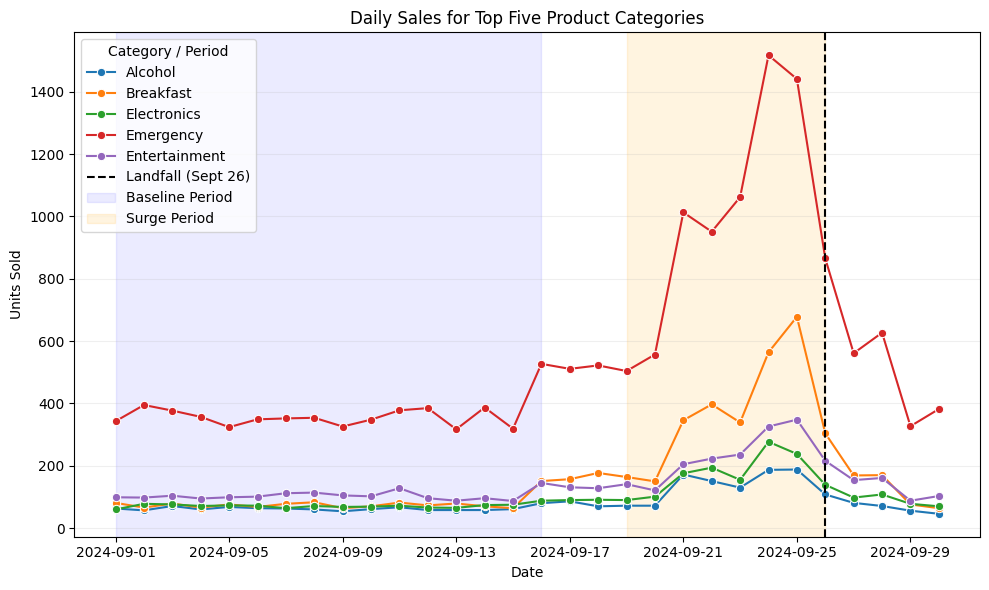

In [46]:
# Q1, Step 6B: Create line chart
fig, ax = plt.subplots(figsize=(10, 6))
sns.lineplot(data=top_daily_sales, x='date', y='units_sold', hue='category', marker='o',ax=ax)

# Mark hurricane landfall
ax.axvline(
    pd.Timestamp('2024-09-26'),
    color='black',
    linestyle='--',
    label='Landfall (Sept 26)'
)

# Highlight baseline period: September 1–15
ax.axvspan(
    pd.Timestamp('2024-09-01'),
    pd.Timestamp('2024-09-16'),
    color='blue',
    alpha=0.08,
    label='Baseline Period'
)

# Highlight surge period: September 19–25
ax.axvspan(
    pd.Timestamp('2024-09-19'),
    pd.Timestamp('2024-09-26'),
    color='orange',
    alpha=0.12,
    label='Surge Period'
)

ax.set_title('Daily Sales for Top Five Product Categories')
ax.set_xlabel('Date')
ax.set_ylabel('Units Sold')
ax.set_xticks(pd.date_range('2024-09-01', '2024-09-30', freq='4D'))
ax.grid(axis='y', alpha=0.2)
ax.legend(title='Category / Period')

plt.tight_layout()
plt.show()

## Question 2: The Pop-Tarts Effect (SKU Consolidation)

> After standardizing all Pop-Tart SKU variants into a single product, what is the true daily sales volume? How does the uncleaned (fragmented) view compare to the cleaned (consolidated) view? What business decisions would differ between the two views?

**Requires:**
- Building an SKU mapping table
- Consolidating fragmented products
- Creating a side-by-side visualization (before vs. after cleaning)
- Writing an analysis of the business impact

In [47]:
# The first two requirements were completed during data cleaning

# Q2, Step 1: Calculate daily units sold for Pop-Tart after SKU consolidation
poptarts_after = clean_transactions[clean_transactions['sku'] == 'POPTART-STRAW']

daily_poptart_sales_after = (
    poptarts_after.dropna(subset=['date'])
    .groupby(['date', 'sku'])['quantity']
    .sum()
    .reset_index(name='units_sold')
)

daily_poptart_sales_after

,date,sku,units_sold
0,2024-09-01,POPTART-STRAW,81
1,2024-09-02,POPTART-STRAW,66
2,2024-09-03,POPTART-STRAW,79
3,2024-09-04,POPTART-STRAW,66
4,2024-09-05,POPTART-STRAW,76
5,2024-09-06,POPTART-STRAW,68
6,2024-09-07,POPTART-STRAW,78
7,2024-09-08,POPTART-STRAW,83
8,2024-09-09,POPTART-STRAW,64
9,2024-09-10,POPTART-STRAW,70


In [48]:
# Q2, Step 2: Identify original Pop-Tart SKU variants
poptarts_before = transactions[transactions['product_name'].str.lower().str.contains('pop')].copy()

# Drop duplicates
poptarts_before = poptarts_before.drop_duplicates()

# Normalize timestamps
poptarts_before['timestamp'] = pd.to_datetime(poptarts_before['timestamp'], errors='coerce', format='mixed')

# Create date column
poptarts_before['date'] = poptarts_before['timestamp'].dt.normalize()


# Convert quantity to numeric
poptarts_before['quantity'] = pd.to_numeric(poptarts_before['quantity'], errors='coerce')
# Remove missing and negative quantities
poptarts_before = poptarts_before.dropna(subset=['quantity'])
poptarts_before = poptarts_before[poptarts_before['quantity'] > 0]

# Remove missing dates
poptarts_before = poptarts_before.dropna(subset=['date'])

# Inspect original SKUs
grouped_poptart_sku = poptarts_before.groupby('sku')['product_name'].first()    # one representative product name for each SKU
display(grouped_poptart_sku)
display(poptarts_before[['sku', 'product_name', 'quantity', 'date']].head())

,product_name
sku,
POPTART-STRAW,Strawberry Pop-Tart
PT-12,Pop Tarts - Strawberry
PT_STRAWBERRY,pop-tarts strawberry
SKU#459812,POPTART-STRAWBERRY


,sku,product_name,quantity,date
21,PT_STRAWBERRY,pop-tarts strawberry,4,2024-09-25
27,SKU#459812,POPTART-STRAWBERRY,4,2024-09-21
29,PT_STRAWBERRY,Strawberry Pop-Tart,3,2024-09-23
47,PT-12,Pop Tarts - Strawberry,3,2024-09-20
52,POPTART-STRAW,Strawberry Pop-Tart,1,2024-09-20


In [49]:
# Q2, Step 3: Calculate daily sales before SKU consolidation
daily_poptart_sales_before = (
    poptarts_before.groupby(['date', 'sku'])['quantity'].sum()
    .reset_index(name='units_sold')
)
daily_poptart_sales_before.head(8)

,date,sku,units_sold
0,2024-09-01,POPTART-STRAW,18
1,2024-09-01,PT-12,30
2,2024-09-01,PT_STRAWBERRY,13
3,2024-09-01,SKU#459812,20
4,2024-09-02,POPTART-STRAW,24
5,2024-09-02,PT-12,23
6,2024-09-02,PT_STRAWBERRY,9
7,2024-09-02,SKU#459812,10


In [50]:
# Q2, Step 4: Verify total units sold before and after
print("Before:", daily_poptart_sales_before['units_sold'].sum())
print("After:", daily_poptart_sales_after['units_sold'].sum())

Before: 5005
After: 5005


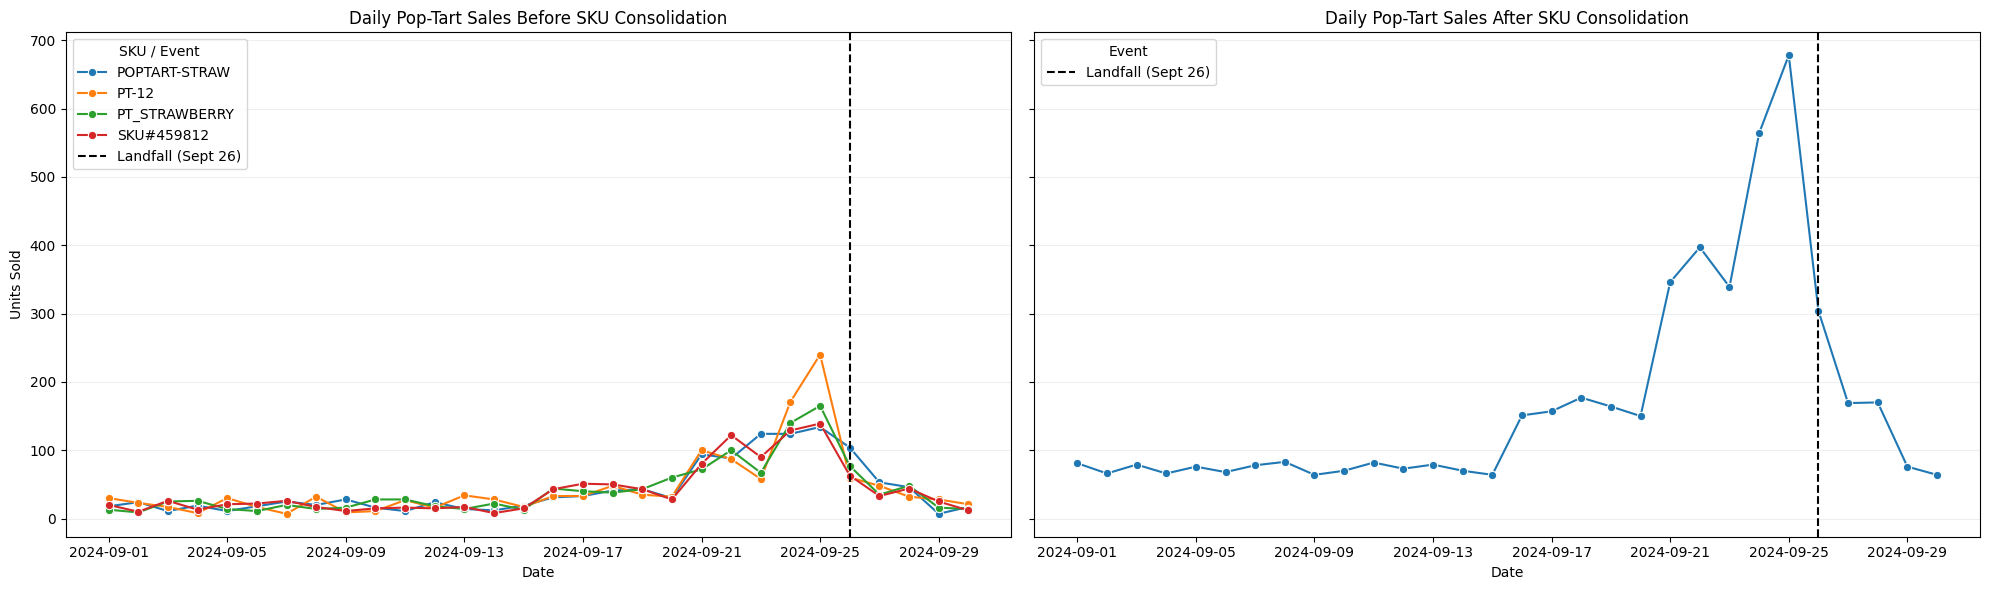

In [51]:
# Q2, Step 5: Create a side-by-side line charts
fig, axs = plt.subplots(ncols=2, figsize=(20,6), sharey=True)

# Before SKU consolidation
sns.lineplot(data=daily_poptart_sales_before, x='date', y='units_sold', hue='sku', marker='o', ax=axs[0])
axs[0].set_title('Daily Pop-Tart Sales Before SKU Consolidation')
axs[0].set_xlabel('Date')
axs[0].set_ylabel('Units Sold')
axs[0].set_xticks(pd.date_range('2024-09-01', '2024-09-30', freq='4D'))
axs[0].axvline(
    pd.Timestamp('2024-09-26'),
    color='black',
    linestyle='--',
    label='Landfall (Sept 26)'
)
axs[0].grid(axis='y', alpha=0.2)
axs[0].legend(title='SKU / Event')

# After
sns.lineplot(data=daily_poptart_sales_after, x='date', y='units_sold', marker='o', ax=axs[1])
axs[1].set_title('Daily Pop-Tart Sales After SKU Consolidation')
axs[1].set_xlabel('Date')
axs[1].set_ylabel('Units Sold')
axs[1].set_xticks(pd.date_range('2024-09-01', '2024-09-30', freq='4D'))
axs[1].axvline(
    pd.Timestamp('2024-09-26'),
    color='black',
    linestyle='--',
    label='Landfall (Sept 26)'
)

axs[1].grid(axis='y', alpha=0.2)
axs[1].legend(title='Event')

plt.tight_layout()
plt.show()


Business decisions would differ between two views.

## Question 3: Weather Correlation Analysis

> Using weather data pulled from your chosen free API, how do specific weather indicators (wind speed, precipitation, barometric pressure) correlate with daily sales volume across categories? Is there a detectable lag between weather severity escalation and purchasing spikes?

**Requires:**
- Integrating a weather API
- Aligning timestamps and timezones
- Performing correlation analysis (scatter plot, heatmap, or time-series overlay)
- Discussing lag analysis


In [52]:
# Question 3, Part 1: Weather-sales correlations

# Verify that the weather data came from the real API
print("Weather source:", weather_live["source"].unique())

if not weather_live["source"].eq("open-meteo").all():
    raise ValueError(
        "Real Open-Meteo data is required for interpreting correlations. "
        "The current weather data includes fallback values."
    )

# Standardize dates and weather column names
weather_q3 = weather_live.copy()
weather_q3["date"] = pd.to_datetime(weather_q3["date"]).dt.normalize()

weather_q3 = weather_q3.rename(columns={
    "wind_speed_10m_max": "windspeed_10m_max"
})

weather_variables = [
    "windspeed_10m_max",
    "precipitation_sum",
    "pressure_msl_mean"
]

# Aggregate transaction quantity by date and category
transactions_q3 = clean_transactions.copy()
transactions_q3["date"] = pd.to_datetime(
    transactions_q3["date"]
).dt.normalize()

daily_category_sales = (
    transactions_q3.dropna(subset=["date", "category"])
    .groupby(["date", "category"], as_index=False)
    .agg(daily_quantity=("quantity", "sum"))
)

# Attach that date's weather observations
daily_category_sales = daily_category_sales.merge(
    weather_q3[["date"] + weather_variables],
    on="date",
    how="left",
    validate="many_to_one"
)

# Calculate one correlation for each category-weather pair
correlation_results = []

for category, group in daily_category_sales.groupby("category"):
    for variable in weather_variables:
        valid = group[["daily_quantity", variable]].dropna()

        correlation_results.append({
            "category": category,
            "weather_indicator": variable,
            "correlation": valid["daily_quantity"].corr(
                valid[variable]
            ),
            "n_days": len(valid)
        })

correlation_df = pd.DataFrame(correlation_results)

Weather source: ['open-meteo']


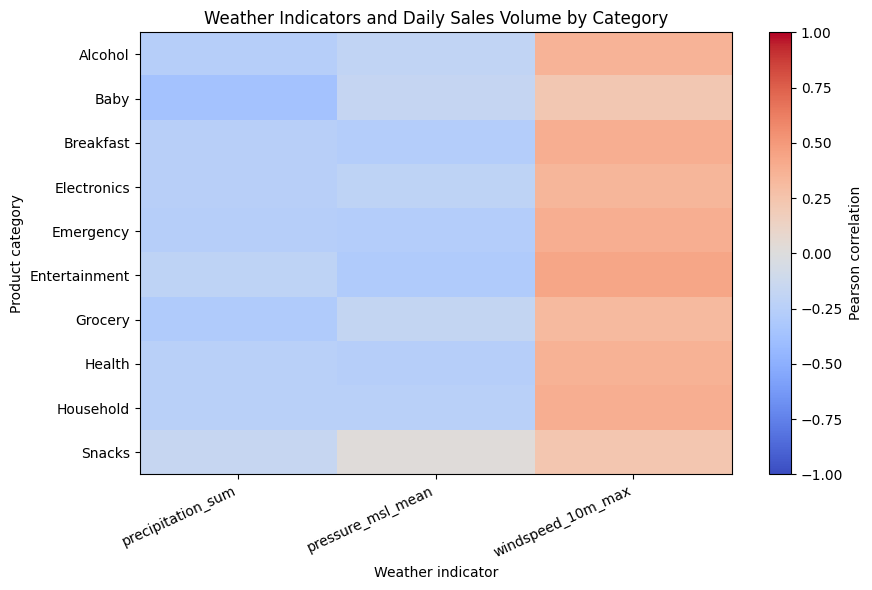

In [53]:
# Heatmap: weather indicators vs. daily sales by category

heatmap_data = correlation_df.pivot(
    index="category",
    columns="weather_indicator",
    values="correlation"
)

plt.figure(figsize=(9, 6))
plt.imshow(
    heatmap_data,
    aspect="auto",
    vmin=-1,
    vmax=1,
    cmap="coolwarm"
)

plt.xticks(
    range(len(heatmap_data.columns)),
    heatmap_data.columns,
    rotation=25,
    ha="right"
)
plt.yticks(range(len(heatmap_data.index)), heatmap_data.index)

plt.colorbar(label="Pearson correlation")
plt.title("Weather Indicators and Daily Sales Volume by Category")
plt.xlabel("Weather indicator")
plt.ylabel("Product category")
plt.tight_layout()
plt.show()

In [54]:
# Question 3, Part 2: Do sales rise BEFORE severe weather?

lead_results = []

for category, group in daily_category_sales.groupby("category"):
    group = group.sort_values("date").copy()

    for variable in weather_variables:
        for days_before in [0, 1, 2, 3]:
            # Match sales today with weather occurring 0–3 days later
            future_weather = group[variable].shift(-days_before)

            comparison = pd.DataFrame({
                "sales": group["daily_quantity"],
                "future_weather": future_weather
            }).dropna()

            lead_results.append({
                "category": category,
                "weather_indicator": variable,
                "days_before_weather": days_before,
                "correlation": comparison["sales"].corr(
                    comparison["future_weather"]
                ),
                "n_days": len(comparison)
            })

lead_df = pd.DataFrame(lead_results)

display(
    lead_df.sort_values(
        ["category", "weather_indicator", "days_before_weather"]
    ).round(3)
)

,category,weather_indicator,days_before_weather,correlation,n_days
4,Alcohol,precipitation_sum,0,-0.259,30
5,Alcohol,precipitation_sum,1,-0.200,29
6,Alcohol,precipitation_sum,2,-0.187,28
7,Alcohol,precipitation_sum,3,-0.114,27
8,Alcohol,pressure_msl_mean,0,-0.190,30
...,...,...,...,...,...
119,Snacks,pressure_msl_mean,3,-0.457,27
108,Snacks,windspeed_10m_max,0,0.233,30
109,Snacks,windspeed_10m_max,1,0.512,29
110,Snacks,windspeed_10m_max,2,0.673,28


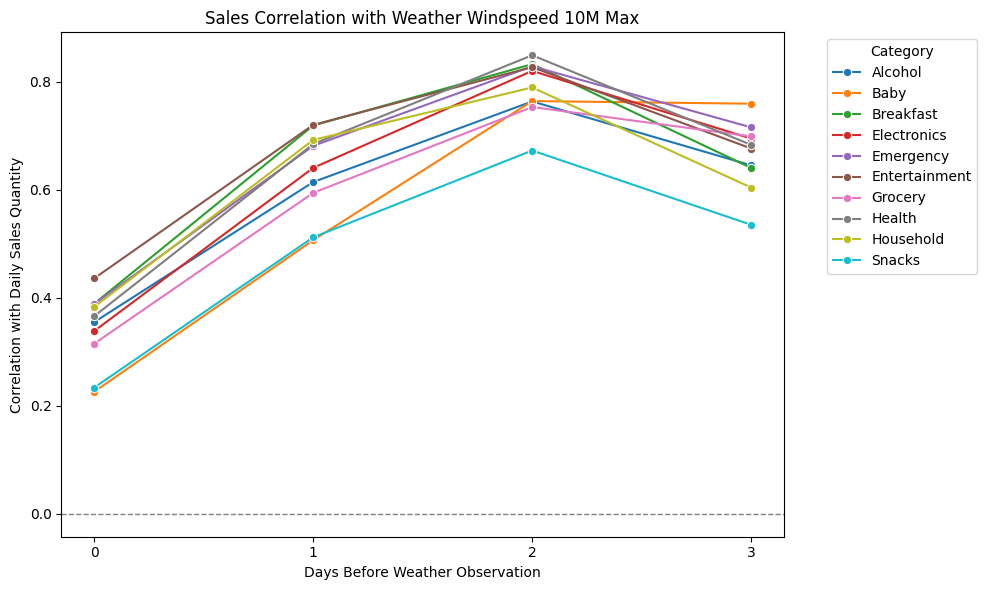

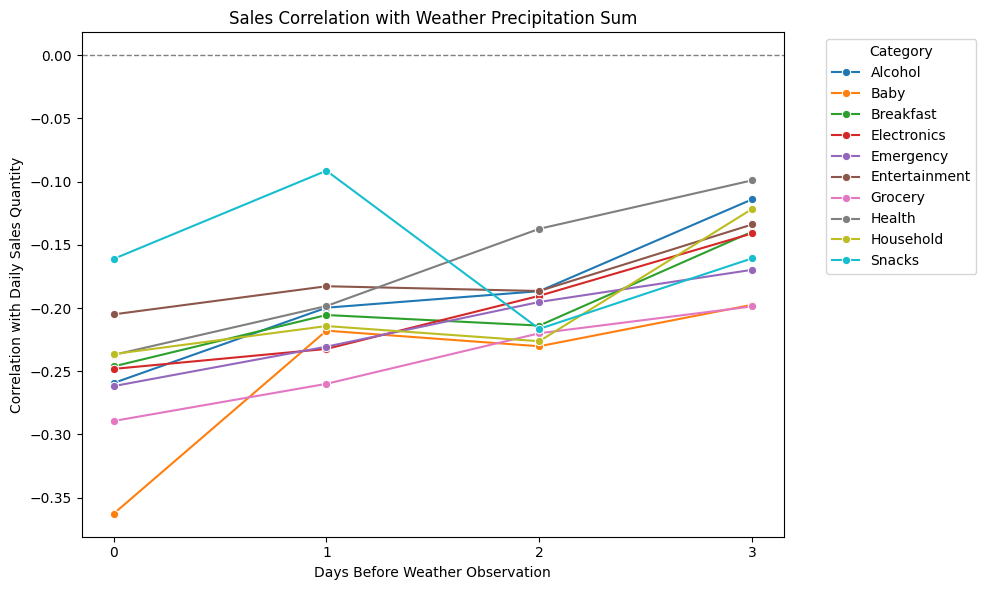

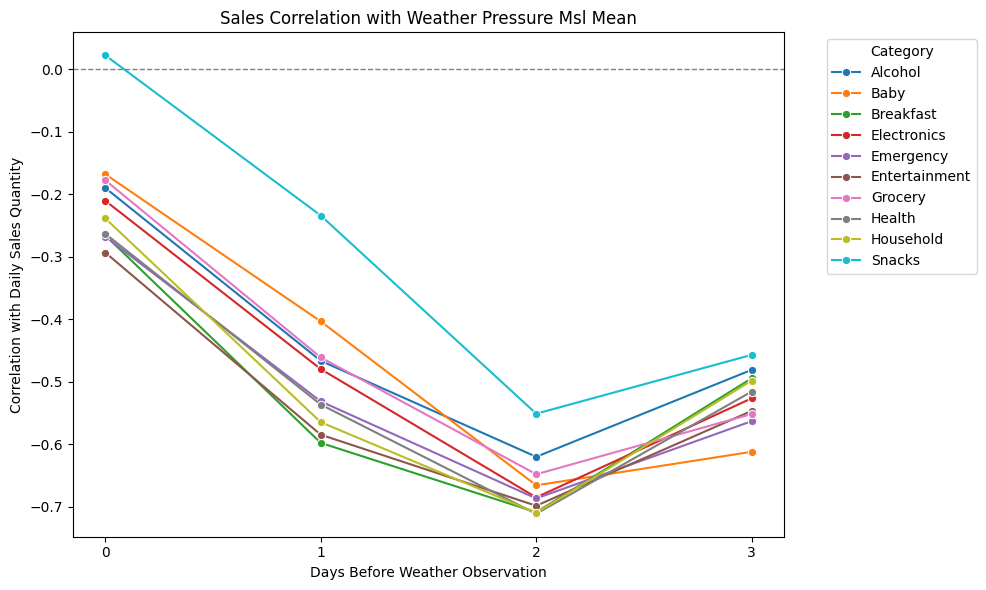

In [55]:
# Visualize correlations between sales and future weather

import matplotlib.pyplot as plt
import seaborn as sns

for variable in weather_variables:
    plot_data = lead_df[
        lead_df["weather_indicator"] == variable
    ]

    plt.figure(figsize=(10, 6))

    sns.lineplot(
        data=plot_data,
        x="days_before_weather",
        y="correlation",
        hue="category",
        marker="o"
    )

    plt.axhline(0, linestyle="--", linewidth=1, color="gray")
    plt.xticks([0, 1, 2, 3])
    plt.xlabel("Days Before Weather Observation")
    plt.ylabel("Correlation with Daily Sales Quantity")
    plt.title(
        f"Sales Correlation with Weather {variable.replace('_', ' ').title()}"
    )
    plt.legend(title="Category", bbox_to_anchor=(1.05, 1), loc="upper left")
    plt.tight_layout()
    plt.show()

## Question 4: Store-Level Geographic Patterns

> Do all Florida store locations experience the same surge patterns, or do stores closer to the predicted hurricane path show earlier and larger spikes? Identify any stores that appear to be outliers.

**Requires:**
- Joining store location data with transactions
- Grouping data geographically
- Comparing surge timing and magnitude across stores
- Creating a bar chart or grouped comparison
- Identifying outliers

In [56]:
# Question 4, Part 1: Join transactions with store locations and define time periods

# Join cleaned transactions with cleaned store locations
q4_data = clean_transactions.merge(
    clean_stores[["store_id", "region", "latitude", "longitude"]],
    on="store_id",
    how="left"
)

# Keep transactions with valid dates and matched store locations
q4_data = q4_data.dropna(subset=["date", "region"])

# Define baseline and surge periods
baseline = q4_data[
    q4_data["date"].between("2024-09-01", "2024-09-15")
]

surge = q4_data[
    q4_data["date"].between("2024-09-21", "2024-09-25")
]

In [57]:
# Question 4, Part 2: Calculate each store's percentage change

# Average daily transaction counts per store
baseline_avg = baseline.groupby("store_id").size() / 15
surge_avg = surge.groupby("store_id").size() / 5

store_comparison = pd.concat(
    [baseline_avg.rename("baseline_avg"),
     surge_avg.rename("surge_avg")],
    axis=1
).fillna(0)

# Calculate percentage change
store_comparison["pct_change"] = (
    (store_comparison["surge_avg"] - store_comparison["baseline_avg"])
    / store_comparison["baseline_avg"].replace(0, np.nan)
    * 100
)

# Add store regions
store_comparison = store_comparison.merge(
    clean_stores[["store_id", "region"]],
    on="store_id",
    how="left"
)

store_comparison.sort_values("pct_change", ascending=False)

,store_id,baseline_avg,surge_avg,pct_change,region
6,FL-330,46.333333,136.0,193.525180,South
11,FL-710,48.200000,139.4,189.211618,Panhandle
2,FL-156,48.066667,138.6,188.349515,East
1,FL-105,47.666667,136.6,186.573427,West
5,FL-302,50.200000,143.6,186.055777,Central
8,FL-445,48.733333,135.2,177.428181,West
7,FL-412,47.533333,131.0,175.596073,North
4,FL-287,47.466667,130.4,174.719101,Central
9,FL-501,48.133333,130.4,170.914127,West
10,FL-619,46.666667,124.6,167.000000,Panhandle


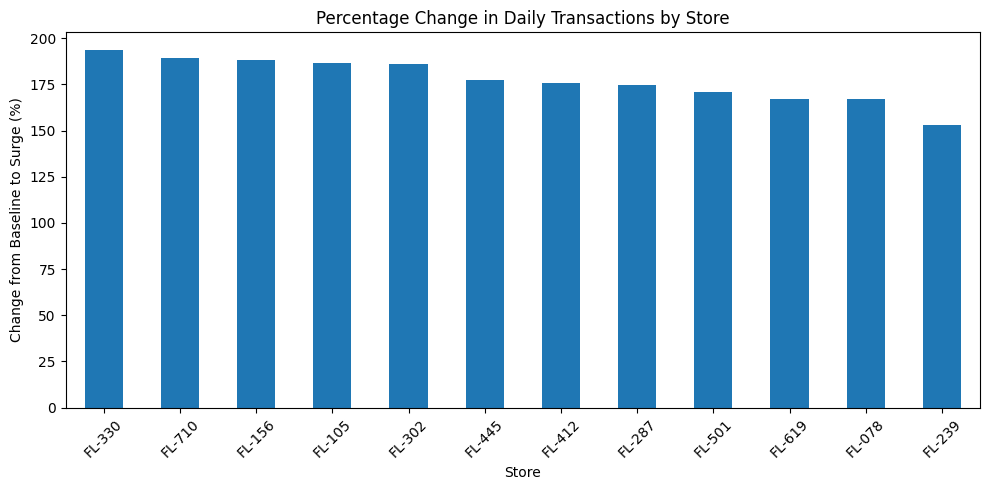

In [58]:
# Question 4, Part 3: Create visualizations of percent increases

top_stores = store_comparison.dropna(
    subset=["pct_change"]
).sort_values("pct_change", ascending=False)

top_stores.plot(
    x="store_id",
    y="pct_change",
    kind="bar",
    legend=False,
    figsize=(10, 5)
)

plt.title("Percentage Change in Daily Transactions by Store")
plt.xlabel("Store")
plt.ylabel("Change from Baseline to Surge (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [59]:
# Question 4, Part 4: Compare regions and identify outliers

region_comparison = (
    store_comparison.groupby("region")["pct_change"]
    .mean()
    .sort_values(ascending=False)
)

print("Average percentage change by region:")
display(region_comparison)

print("\nStores with the largest increases:")
display(top_stores[["store_id", "region", "baseline_avg",
                    "surge_avg", "pct_change"]].head())

print("\nStores with the smallest increases:")
display(top_stores[["store_id", "region", "baseline_avg",
                    "surge_avg", "pct_change"]].tail())

Average percentage change by region:


,pct_change
region,
South,193.525180
East,188.349515
West,178.305245
Panhandle,178.105809
North,171.223451
Central,171.185475



Stores with the largest increases:


,store_id,region,baseline_avg,surge_avg,pct_change
6,FL-330,South,46.333333,136.0,193.525180
11,FL-710,Panhandle,48.200000,139.4,189.211618
2,FL-156,East,48.066667,138.6,188.349515
1,FL-105,West,47.666667,136.6,186.573427
5,FL-302,Central,50.200000,143.6,186.055777



Stores with the smallest increases:


,store_id,region,baseline_avg,surge_avg,pct_change
4,FL-287,Central,47.466667,130.4,174.719101
9,FL-501,West,48.133333,130.4,170.914127
10,FL-619,Panhandle,46.666667,124.6,167.000000
0,FL-078,North,48.266667,128.8,166.850829
3,FL-239,Central,49.133333,124.2,152.781547


## Question 5: Signal vs. Artifact — The Board Games Investigation

> The board games/entertainment category shows a +250% sales increase. Using the SQLite inventory and sales database, investigate whether this is a genuine demand signal or a data artifact (e.g., SKU miscoding, category lumping, inventory reporting lag). Present your evidence and make a recommendation: should Walmart stock extra board games for the next storm?

**Requires:**
- Querying the SQLite database with `sqlite3` and `pandas`
- Cross-referencing with the transaction CSV
- Auditing SKUs and categories
- Presenting an evidence-based written argument
- Creating a supporting visualization

In [60]:
# Q5, Step 1: Load the SQLite sales and inventory tables

# Connect to the SQLite database
conn = sqlite3.connect("inventory_and_sales.db")

# Read both tables into pandas DataFrames
sales_db = pd.read_sql_query(
    "SELECT * FROM daily_sales_summary",
    conn
)

inventory_db = pd.read_sql_query(
    "SELECT * FROM inventory_levels",
    conn
)

# Standardize the date columns
sales_db["date"] = pd.to_datetime(
    sales_db["date"], format="mixed", errors="coerce"
).dt.normalize()

inventory_db["date"] = pd.to_datetime(
    inventory_db["date"], format="mixed", errors="coerce"
).dt.normalize()

print("Daily sales summary:")
display(sales_db.head())

print("Inventory levels:")
display(inventory_db.head())

print("Sales table shape:", sales_db.shape)
print("Inventory table shape:", inventory_db.shape)

Daily sales summary:


,date,store_id,category,total_units,total_revenue
0,2024-09-12,FL-239,Emergency,90.0,1582.55
1,2024-09-12,FL-239,Breakfast,57.0,356.99
2,2024-09-12,FL-239,Alcohol,41.0,246.65
3,2024-09-12,FL-239,Entertainment,53.0,916.56
4,2024-09-12,FL-239,Grocery,69.0,339.30


Inventory levels:


,date,store_id,sku,units_on_hand,units_on_order,reorder_point
0,2024-09-12,FL-239,CHIPS-VP,112,5.0,31
1,2024-09-12,FL-239,PAPERTOWEL6,106,46.0,36
2,2024-09-12,FL-239,PT-12,62,36.0,30
3,2024-09-12,FL-239,PORTCHARGER,185,62.0,40
4,2024-09-12,FL-239,BFORM-01,88,1.0,35


Sales table shape: (3600, 5)
Inventory table shape: (4320, 6)


In [61]:
# Q5, Step 2: Compare Entertainment sales in the database and CSV

# Define the two time periods
baseline_dates = pd.date_range("2024-09-01", "2024-09-15", freq="D")
surge_dates = pd.date_range("2024-09-19", "2024-09-25", freq="D")
analysis_dates = pd.date_range("2024-09-01", "2024-09-25", freq="D")


def compare_periods(daily_sales):
    """Calculate average daily units in the baseline and surge periods."""
    daily_sales = daily_sales.reindex(analysis_dates, fill_value=0)

    baseline_avg = daily_sales.reindex(
        baseline_dates, fill_value=0
    ).mean()

    surge_avg = daily_sales.reindex(
        surge_dates, fill_value=0
    ).mean()

    pct_change = (
        (surge_avg - baseline_avg) / baseline_avg * 100
        if baseline_avg > 0 else np.nan
    )

    return baseline_avg, surge_avg, pct_change


# Database: sum Entertainment units across stores for each date
db_entertainment = (
    sales_db[sales_db["category"].astype(str).str.strip().str.casefold()
             == "entertainment"]
    .groupby("date")["total_units"]
    .sum()
)

db_baseline, db_surge, db_pct = compare_periods(db_entertainment)


# Transaction CSV: use the notebook's existing cleaned transactions
csv_q5 = clean_transactions.copy()

csv_q5["date"] = pd.to_datetime(
    csv_q5["date"], errors="coerce"
).dt.normalize()

csv_entertainment = (
    csv_q5[
        csv_q5["category"].astype(str).str.strip().str.casefold()
        == "entertainment"
    ]
    .dropna(subset=["date"])
    .groupby("date")["quantity"]
    .sum()
)

csv_baseline, csv_surge, csv_pct = compare_periods(csv_entertainment)


# Display results side by side
category_comparison = pd.DataFrame([
    {
        "source": "SQLite daily sales summary",
        "baseline_daily_avg": db_baseline,
        "surge_daily_avg": db_surge,
        "percent_change": db_pct
    },
    {
        "source": "Cleaned transaction CSV",
        "baseline_daily_avg": csv_baseline,
        "surge_daily_avg": csv_surge,
        "percent_change": csv_pct
    }
])

display(category_comparison.round(2))

,source,baseline_daily_avg,surge_daily_avg,percent_change
0,SQLite daily sales summary,568.47,1394.50,145.31
1,Cleaned transaction CSV,101.60,228.57,124.97


In [62]:
# Q5, Step 3: Audit Entertainment products and original SKU labels

# Review Entertainment products in the already-cleaned product catalog
entertainment_products = clean_products[
    clean_products["category"].astype(str).str.strip().str.casefold()
    == "entertainment"
].copy()

catalog_columns = [
    col for col in [
        "sku", "product_name", "category", "subcategory",
        "unit_cost", "supplier", "package_size"
    ]
    if col in entertainment_products.columns
]

print("Entertainment products in the cleaned catalog:")
display(
    entertainment_products[catalog_columns]
    .sort_values("sku")
    .drop_duplicates()
)


# Examine the original, uncleaned transaction data to retain original SKU labels
raw_q5 = transactions.copy()

raw_q5["sku_original"] = (
    raw_q5["sku"].astype(str).str.strip().str.upper()
)

# Map known legacy SKU names to the canonical SKU names used in the notebook
raw_q5["sku_canonical"] = (
    raw_q5["sku_original"].map(SKU_MAP)
    .fillna(raw_q5["sku_original"])
)

# Focus on board games and playing cards
game_skus = ["BG-MONO-01", "CARDS-01"]

raw_game_transactions = raw_q5[
    raw_q5["sku_canonical"].isin(game_skus)
].copy()

print("Original SKU variants in the transaction CSV:")
display(
    raw_game_transactions.groupby(
        ["sku_canonical", "sku_original", "category"],
        dropna=False
    )
    .agg(
        transaction_rows=("transaction_id", "size"),
        total_quantity=("quantity", "sum")
    )
    .reset_index()
    .sort_values(["sku_canonical", "sku_original", "category"])
)

Entertainment products in the cleaned catalog:


,sku,product_name,category,subcategory,unit_cost,supplier,package_size
14,BG-MONO-01,Monopoly Board Game,Entertainment,Board Games,9.96,Hasbro,1-pack
15,BG-MONO-01,Monopoly Board Game,Entertainment,Board Games,12.51,Hasbro,1-pack
16,BG-MONO-01,Monopoly Board Game,Entertainment,Board Games,NaN,Hasbro,1-pack
17,CARDS-01,Playing Cards,Entertainment,Card Games,2.45,Hasbro,1-pack
18,CARDS-01,Playing Cards,Entertainment,Card Games,2.39,Hasbro,1-pack


Original SKU variants in the transaction CSV:


,sku_canonical,sku_original,category,transaction_rows,total_quantity
0,BG-MONO-01,BG-MONO,ENTERTAINMENT,110,159
1,BG-MONO-01,BG-MONO,Entertainment,112,176
2,BG-MONO-01,BG-MONO,Games & Entertainment,100,157
3,BG-MONO-01,BG-MONO,entertainment,113,162
4,BG-MONO-01,GAME-MONO,ENTERTAINMENT,113,163
5,BG-MONO-01,GAME-MONO,Entertainment,106,167
6,BG-MONO-01,GAME-MONO,Games & Entertainment,122,194
7,BG-MONO-01,GAME-MONO,entertainment,125,176
8,BG-MONO-01,MONOPOLY-01,ENTERTAINMENT,102,154
9,BG-MONO-01,MONOPOLY-01,Entertainment,114,174


In [63]:
# Q5, Step 4: Calculate board-game and playing-card sales changes

game_products = {
    "BG-MONO-01": "Monopoly Board Game",
    "CARDS-01": "Playing Cards"
}

# Keep transactions for the two canonical products
games = clean_transactions[
    clean_transactions["sku"].isin(game_products.keys())
    & clean_transactions["date"].notna()
].copy()

games["date"] = pd.to_datetime(
    games["date"], errors="coerce"
).dt.normalize()

# Total units sold per day and canonical SKU
daily_games = (
    games.groupby(["date", "sku"])["quantity"]
    .sum()
    .unstack("sku", fill_value=0)
)

# Ensure each product has a column and all dates are present
daily_games = daily_games.reindex(
    index=analysis_dates,
    columns=game_products.keys(),
    fill_value=0
)

game_results = []

for sku, product_name in game_products.items():
    daily = daily_games[sku]

    baseline_avg = daily.reindex(
        baseline_dates, fill_value=0
    ).mean()

    surge_avg = daily.reindex(
        surge_dates, fill_value=0
    ).mean()

    pct_change = (
        (surge_avg - baseline_avg) / baseline_avg * 100
        if baseline_avg > 0 else np.nan
    )

    game_results.append({
        "sku": sku,
        "product": product_name,
        "baseline_daily_avg": baseline_avg,
        "surge_daily_avg": surge_avg,
        "percent_change": pct_change
    })

game_comparison = pd.DataFrame(game_results)

display(game_comparison.round(2))

,sku,product,baseline_daily_avg,surge_daily_avg,percent_change
0,BG-MONO-01,Monopoly Board Game,42.87,111.43,159.94
1,CARDS-01,Playing Cards,58.73,117.14,99.45


In [64]:
# Q5, Step 5: Audit inventory SKU variants and snapshot collisions

inventory_q5 = inventory_db.copy()

inventory_q5["sku_original"] = (
    inventory_q5["sku"].astype(str).str.strip().str.upper()
)

inventory_q5["sku_canonical"] = (
    inventory_q5["sku_original"].map(SKU_MAP)
    .fillna(inventory_q5["sku_original"])
)

# Summarize the original SKU variants for the two game-related products
game_inventory = inventory_q5[
    inventory_q5["sku_canonical"].isin(game_products.keys())
].copy()

print("Inventory summary by canonical product and original SKU:")
display(
    game_inventory.groupby(
        ["sku_canonical", "sku_original"]
    )
    .agg(
        snapshot_rows=("sku_original", "size"),
        avg_units_on_hand=("units_on_hand", "mean"),
        avg_units_on_order=("units_on_order", "mean"),
        avg_reorder_point=("reorder_point", "mean")
    )
    .reset_index()
    .round(2)
)


# Check whether multiple raw SKU rows map to the same store/date/product
snapshot_counts = (
    inventory_q5.groupby(
        ["date", "store_id", "sku_canonical"],
        dropna=False
    )
    .size()
    .rename("raw_sku_rows")
    .reset_index()
)

collisions = snapshot_counts[
    snapshot_counts["raw_sku_rows"] > 1
].copy()

game_collisions = collisions[
    collisions["sku_canonical"].isin(game_products.keys())
]

print("All canonical inventory snapshot groups:", len(snapshot_counts))
print("Groups with multiple raw SKU rows:", len(collisions))
print("Game-product groups with multiple raw SKU rows:", len(game_collisions))

print("\nExamples of potentially ambiguous game inventory snapshots:")
display(game_collisions.head(15))

Inventory summary by canonical product and original SKU:


,sku_canonical,sku_original,snapshot_rows,avg_units_on_hand,avg_units_on_order,avg_reorder_point
0,BG-MONO-01,BG-MONO,93,77.71,50.22,34.82
1,BG-MONO-01,GAME-MONO,92,71.97,52.04,33.40
2,BG-MONO-01,MONOPOLY-01,92,88.95,48.83,34.12
3,CARDS-01,CARDS-01,96,80.07,46.31,34.51
4,CARDS-01,PLAYCARD-STD,73,81.53,47.53,34.96


All canonical inventory snapshot groups: 3726
Groups with multiple raw SKU rows: 564
Game-product groups with multiple raw SKU rows: 69

Examples of potentially ambiguous game inventory snapshots:


,date,store_id,sku_canonical,raw_sku_rows
11,2024-09-01,FL-105,BG-MONO-01,2
21,2024-09-01,FL-156,BG-MONO-01,2
60,2024-09-01,FL-330,BG-MONO-01,2
61,2024-09-01,FL-330,CARDS-01,2
193,2024-09-02,FL-412,BG-MONO-01,2
297,2024-09-03,FL-302,BG-MONO-01,2
306,2024-09-03,FL-330,CARDS-01,2
476,2024-09-04,FL-710,CARDS-01,2
537,2024-09-05,FL-302,BG-MONO-01,2
616,2024-09-06,FL-105,BG-MONO-01,3


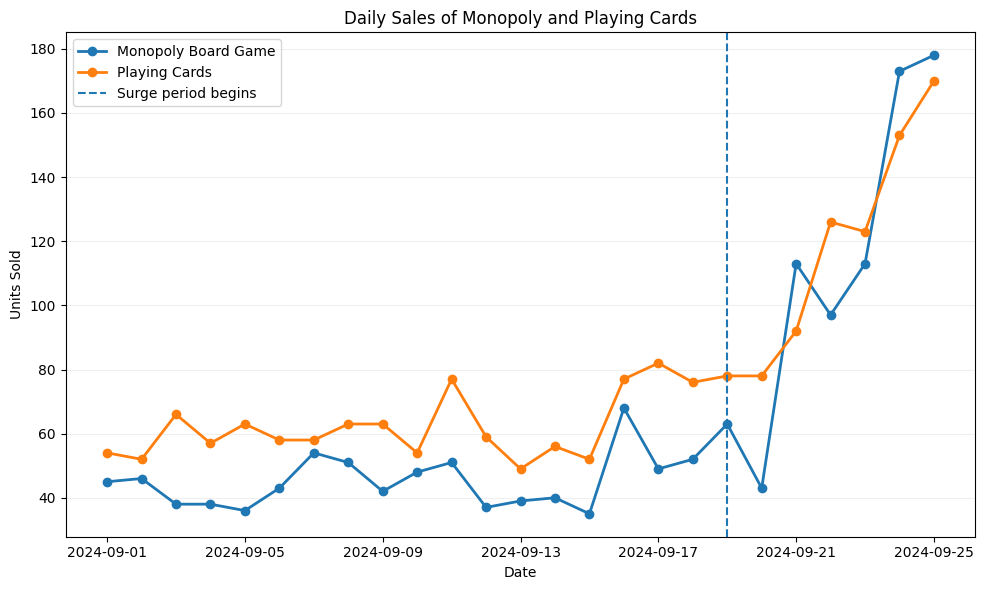

In [65]:
# Q5, Step 6: Visualize daily sales for board games and playing cards

fig, ax = plt.subplots(figsize=(10, 6))

for sku, product_name in game_products.items():
    ax.plot(
        daily_games.index,
        daily_games[sku],
        marker="o",
        linewidth=2,
        label=product_name
    )

# Mark the start of the surge window
ax.axvline(
    pd.Timestamp("2024-09-19"),
    linestyle="--",
    linewidth=1.5,
    label="Surge period begins"
)

ax.set_title("Daily Sales of Monopoly and Playing Cards")
ax.set_xlabel("Date")
ax.set_ylabel("Units Sold")
ax.legend()
ax.grid(axis='y', alpha=0.2)


plt.tight_layout()
plt.show()

In [66]:
# Q5, Step 7: Print the main evidence for the written recommendation

print("1. CATEGORY-LEVEL COMPARISON")
display(category_comparison.round(2))

print("\n2. PRODUCT-LEVEL COMPARISON")
display(game_comparison.round(2))

print("\n3. SKU / INVENTORY AUDIT")
print("Number of canonical inventory snapshot groups:", len(snapshot_counts))
print("Groups containing multiple raw SKU rows:", len(collisions))
print("Game-product groups containing multiple raw SKU rows:", len(game_collisions))

1. CATEGORY-LEVEL COMPARISON


,source,baseline_daily_avg,surge_daily_avg,percent_change
0,SQLite daily sales summary,568.47,1394.50,145.31
1,Cleaned transaction CSV,101.60,228.57,124.97



2. PRODUCT-LEVEL COMPARISON


,sku,product,baseline_daily_avg,surge_daily_avg,percent_change
0,BG-MONO-01,Monopoly Board Game,42.87,111.43,159.94
1,CARDS-01,Playing Cards,58.73,117.14,99.45



3. SKU / INVENTORY AUDIT
Number of canonical inventory snapshot groups: 3726
Groups containing multiple raw SKU rows: 564
Game-product groups containing multiple raw SKU rows: 69
